## 1. Dataset

### Download the dataset
The dataset is available at: https://www.ksh.hu/stadat_files/gsz/hu/gsz0018.html  
It can be downloaded from "Menü" in .xlsx and in .csv

### Description of the dataset
I will be working with the Hungarian Central Statistical Office's dataset on enterprise performance indicators by small and medium enterprise (SME) categories. I focus on the analysis from company developmet's perspective.
This official KSH dataset tracks core business health indicators across Hungarian enterprises, with detailed breakdowns by size category from 2013-2023.

**ML approaches the data is mostly suited for**
1. **Unsupervised learning:** The dataset provides multi-indicator, multi-year, and multi-segment numeric vectors, which are well suited for structural discovery and regime analysis rather than detailed point predictions.
    - Clustering can be applied to identify groups either by year to discover temporal trends or by SME size categories to quantify characteristic differences across segments
    - Dimensionality reduction techniques such as PCA help extract the main axes of variation (e.g., export orientation, capital intensity), enabling clear visualization of development trajectories and interpretation of feature contributions.

2. **Supervised regression**: The features are continuous and economically meaningful, warranting regression approaches with appropriate validation.
   - Due to the limited sample size and multi-year nature, supervised models like linear regression with regularization can be effective when labels are available. However, in the absence of explicit target variables, unsupervised ensemble methods such as Isolation Forest are more appropriate for identifying patterns and anomalies in the data.
   - While time-aware validation with chronological splits is ideal, in this work a stratified random train-test split was used to ensure balanced sample representation across size categories and years, which supports model development while acknowledging limitations related to temporal dependencies. Future work may consider more robust temporal validation strategies

**The features used from the dataset:**
- Enterprise size category (categorical)
- Year (temporal)
- Number of enterprises (numerical)
- Number of employees (numerical)
- Employee distribution (ratio)
- Revenue per employee (numerical)
- Net sales revenue (numerical)
- Value added (numerical)
- Export sales revenue (numerical)
- National economic investment (numerical)

In [1]:
import pandas as pd

# Only read relevant data
df_gsz18 = pd.read_excel(
    "./resources/stadat-gsz0018-9.1.1.17-hu.xlsx",
    sheet_name="9.1.1.17.",
    skiprows=1,
    usecols=[
        'Kis- és középvállalkozási kategória',
        'Vállalkozások száma, darab',
        'Foglalkoztatottak létszáma, fő',
        'Egy foglalkoztatottra jutó árbevétel, ezer forint/fő',
        'Foglalkoztatottak létszámának megoszlása, %',
        'Értékesítés nettó árbevétele, millió forint',
        'Hozzáadott érték, millió forint',
        'Export-értékesítés árbevétele, millió forint',
        'Nemzetgazdasági beruházás, millió forint'    ]
)

# Rename columns to English
column_rename_map = {
    'Kis- és középvállalkozási kategória': 'Company Size Category',
    'Vállalkozások száma, darab': 'Number of Enterprises',
    'Foglalkoztatottak létszáma, fő': 'Number of Employees',
    'Egy foglalkoztatottra jutó árbevétel, ezer forint/fő': 'Revenue per Employee (thousand HUF/person)',
    'Foglalkoztatottak létszámának megoszlása, %': 'Employee Distribution (%)',
    'Értékesítés nettó árbevétele, millió forint': 'Net Sales Revenue (million HUF)',
    'Hozzáadott érték, millió forint': 'Value added (million HUF)',
    'Export-értékesítés árbevétele, millió forint': 'Export Sales Revenue (million HUF)',
    'Nemzetgazdasági beruházás, millió forint': 'National economic investment (million HUF)'
}
df_gsz18.rename(columns=column_rename_map, inplace=True)

## Make the dataset tidy ##

is_year = df_gsz18['Company Size Category'].astype(str).str.strip().str.match(r'^\d{4}$')
years = df_gsz18[is_year]['Company Size Category'].to_list()

# Add years as column (repeated for all 7 categories)
df_gsz18_data = df_gsz18[~is_year].reset_index(drop=True)
year_col = []
for y in years:
    year_col.extend([int(y)] * 7)
df_gsz18_data['Year'] = year_col

# Melt year to long format
value_vars = [col for col in df_gsz18_data.columns if col not in ['Company Size Category', 'Year']]
df_gsz18_final = pd.melt(df_gsz18_data,
                  id_vars=['Year', 'Company Size Category'],
                  value_vars=value_vars,
                  var_name='Indicator',
                  value_name='Value')

# Change company categories to English and create categorical variable
gsz18_category_order = [
    'Micro (0 employee)',
    'Micro (1 employee)',
    'Micro (2-9 employees)',
    'Small',
    'Medium',
    'Non-SME organization',
    'Total'
]

df_gsz18_final['Company Size Category'] = df_gsz18_final['Company Size Category'].str.strip()
gsz18_category_map = {
    '0 fős mikrovállalkozások': gsz18_category_order[0],
    '1 fős mikrovállalkozások': gsz18_category_order[1],
    '2–9 fős mikrovállalkozások': gsz18_category_order[2],
    'Kisvállalkozások': gsz18_category_order[3],
    'Középvállalkozások': gsz18_category_order[4],
    'Nem KKV körbe tartozó szervezetek': gsz18_category_order[5],
    'Összesen': gsz18_category_order[6]
}

df_gsz18_final['Company Size Category'] = df_gsz18_final['Company Size Category'].map(gsz18_category_map)

df_gsz18_final['Company Size Category'] = pd.Categorical(
    df_gsz18_final['Company Size Category'],
    categories=gsz18_category_order,
    ordered=True
)

df_gsz18_final.head()

,Year,Company Size Category,Indicator,Value
0,2013,Micro (0 employee),Number of Enterprises,9220.0
1,2013,Micro (1 employee),Number of Enterprises,392914.0
2,2013,Micro (2-9 employees),Number of Enterprises,173174.0
3,2013,Small,Number of Enterprises,29197.0
4,2013,Medium,Number of Enterprises,4961.0


#### Handle invalid values

In [2]:
# Make sure Year is numeric
pd.to_numeric(df_gsz18_final['Year'], errors='coerce').notna().all()

np.True_

In [3]:
# Value should be numerical too
df_gsz18_final['Value'] = pd.to_numeric(df_gsz18_final['Value'], errors='coerce')

# Check NaN
df_gsz18_final[ df_gsz18_final['Value'].isna()]

,Year,Company Size Category,Indicator,Value
77,2013,Micro (0 employee),Number of Employees,NaN
84,2014,Micro (0 employee),Number of Employees,NaN
91,2015,Micro (0 employee),Number of Employees,NaN
98,2016,Micro (0 employee),Number of Employees,NaN
105,2017,Micro (0 employee),Number of Employees,NaN
112,2018,Micro (0 employee),Number of Employees,NaN
119,2019,Micro (0 employee),Number of Employees,NaN
126,2020,Micro (0 employee),Number of Employees,NaN
133,2021,Micro (0 employee),Number of Employees,NaN
140,2022,Micro (0 employee),Number of Employees,NaN


0-employee companies don't have values for the following three indicators:
- Number of Employees
- Revenue per Employee (thousand HUF/person)
- Employee Distribution (%)

As there are 0 employees, it makes sense to fill these values with 0, and then we can run the models without any problem.

In [4]:
df_gsz18_final['Value'] = df_gsz18_final['Value'].fillna(0)

**Inspect the dataset**

In [5]:
indicators = df_gsz18_final.loc[:, 'Indicator'].dropna().unique().tolist()
indicators

['Number of Enterprises',
 'Number of Employees',
 'Revenue per Employee (thousand HUF/person)',
 'Employee Distribution (%)',
 'Net Sales Revenue (million HUF)',
 'Value added (million HUF)',
 'Export Sales Revenue (million HUF)',
 'National economic investment (million HUF)']

In [6]:
print("Structure Dataset Dimensions:", df_gsz18_final.shape)
print("\nAvailable Years:\n", ", ".join(map(str, sorted(df_gsz18_final['Year'].unique()))))
print("\nSize Categories:\n", ", ".join(df_gsz18_final['Company Size Category'].unique()))
print("\nIndicator Categories:\n", ", ".join(df_gsz18_final['Indicator'].unique()))
print(f"\nNumber of NaNs:\n {df_gsz18_final.isna().sum()}")
df_gsz18_final

Structure Dataset Dimensions: (616, 4)

Available Years:
 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023

Size Categories:
 Micro (0 employee), Micro (1 employee), Micro (2-9 employees), Small, Medium, Non-SME organization, Total

Indicator Categories:
 Number of Enterprises, Number of Employees, Revenue per Employee (thousand HUF/person), Employee Distribution (%), Net Sales Revenue (million HUF), Value added (million HUF), Export Sales Revenue (million HUF), National economic investment (million HUF)

Number of NaNs:
 Year                     0
Company Size Category    0
Indicator                0
Value                    0
dtype: int64


,Year,Company Size Category,Indicator,Value
0,2013,Micro (0 employee),Number of Enterprises,9220.000
1,2013,Micro (1 employee),Number of Enterprises,392914.000
2,2013,Micro (2-9 employees),Number of Enterprises,173174.000
3,2013,Small,Number of Enterprises,29197.000
4,2013,Medium,Number of Enterprises,4961.000
...,...,...,...,...
611,2023,Micro (2-9 employees),National economic investment (million HUF),206476.090
612,2023,Small,National economic investment (million HUF),704286.187
613,2023,Medium,National economic investment (million HUF),1465033.344
614,2023,Non-SME organization,National economic investment (million HUF),6466366.053


## 2. Models

Instantiate and train three different classes of models presented in the course in the cells below the corresponding header.

**At least ONE of the models must be from topic 5 and after.**

You are free to use `scikit-learn` and other packages where necessary.  

### Prepare data for models 

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Change my data to wide format
wide_df = df_gsz18_final.pivot_table(
    index = ['Year', 'Company Size Category'],
    columns = 'Indicator',
    values = 'Value',
    observed=False
).reset_index()

# Remove total
wide_df = wide_df[ wide_df['Company Size Category'] != 'Total' ]

# It's important to standardise fearures as models using distances are very sensitive to scales (e.g. K-means, PCA)
# Scaling also helps comparing the models later, and it doesn't hurt models that are not sensitive
def scaled_train_test_split(test_size = 0.2):
    """
    Splits the dataset into scaled training and test sets for model input.
    Note that this is a random and not a time-based split.

    Parameters
    ----------
    test_size : float, optional
        Fraction of the dataset to reserve for testing (default is 0.2)

    Returns
    -------
    X_train_scaled : numpy.ndarray
        Scaled training feature matrix.
    X_test_scaled : numpy.ndarray
        Scaled test feature matrix.
    """
    X_train, X_test = train_test_split(wide_df[indicators], test_size = test_size, random_state = 42)

    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled

# Make sure test and train are separated from the beginning
X_train, X_test = scaled_train_test_split()

### 2.1 Model I: PCA<sup>1</sup>

Implement your first model and fit the dataset you loaded above. 

In [8]:
from sklearn.decomposition import PCA

def get_train_test_pca(X_train, X_test, n = 4):
    """
    Fits PCA to training data and transforms both train and test sets.

    Parameters
    ----------
    X_train : numpy.ndarray
        The training data matrix to fit PCA on.
    X_test : numpy.ndarray
        The test data matrix to transform using the fitted PCA.
    n : int, optional
        Number of principal components to retain (default 4).

    Returns
    -------
    X_train_pca : numpy.ndarray
        PCA transformed training data.
    X_test_pca : numpy.ndarray
        PCA transformed test data.
    pca : sklearn.decomposition.PCA
        The fitted PCA object.
    """
    pca = PCA(n_components = n, svd_solver = 'randomized', random_state = 42)
    pca.fit(X_train)
    X_train_pca = pca.transform(X_train)
    X_test_pca = pca.transform(X_test)

    return X_train_pca, X_test_pca, pca

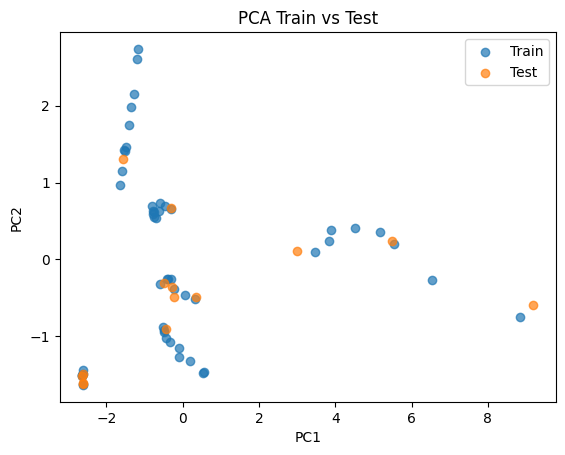

In [9]:
import matplotlib.pyplot as plt 

# Run with default n = 4
X_train_pca, X_test_pca, pca = get_train_test_pca(X_train = X_train, X_test = X_test)

plt.scatter(X_train_pca[:,0], X_train_pca[:,1], label='Train', alpha=0.7)
plt.scatter(X_test_pca[:,0], X_test_pca[:,1], label='Test', alpha=0.7)
plt.legend()
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Train vs Test')
plt.show()

The scatter plots compares the train and test samples after PCA dimensionality reduction on the first two principal components (PC1 and PC2). The train and test points are both well spread out across the range of PC1, with overlap and similar coverage along PC2. No strong clustering or separation is apparent between the train and test subsets, suggesting that:
- The data splitting has maintained the underlying distribution of the original dataset
- There is no visible data leakage or unintentional bias in the train/test split
- Models built on these principal components should be able to generalize from the train set to unseen test data, since test samples fall in similar regions as the train set  

This balanced spread and overlap between train and test indicate a reliable PCA transformation and valid train-test partition, well supporting further machine learning analyses.<sup>2</sup>

### 2.2 Model II: K-Means Clustering<sup>3</sup>

Implement your second model and fit the dataset you loaded above. 

In [10]:
from sklearn.cluster import KMeans

def train_pred_k_means(X_train, X_test, k = 4):
    """
    Trains a K-Means clustering model on training data and predicts cluster labels for train and test.

    Parameters
    ----------
    X_train : numpy.ndarray
        Training feature data (should be scaled).
    X_test : numpy.ndarray
        Test feature data (should be scaled).
    k : int, optional
        Number of K-Means clusters (default is 4).

    Returns
    -------
    train_labels : numpy.ndarray
        Cluster labels predicted for training data.
    test_labels : numpy.ndarray
        Cluster labels predicted for test data.
    kmeans : sklearn.cluster.KMeans
        The fitted K-Means clustering model.
    """
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit(X_train)

    train_labels = kmeans.predict(X_train)
    test_labels = kmeans.predict(X_test)
    
    return train_labels, test_labels, kmeans

In [11]:
import numpy as np

k_means_train_labels, k_means_test_labels, kmeans = train_pred_k_means(X_train, X_test)
unique, counts = np.unique(k_means_train_labels, return_counts=True)
print(dict(zip(unique, counts)))

{np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


The cluster assignments from K-means partition the train and test datasets into distinct groups based on feature similarity. The distribution of train samples across clusters (e.g., clusters 0 to 3) shows how the data is segmented by the algorithm.  

While clusters are distinct by definition, the cluster sizes are reasonably balanced without extreme skew, indicating meaningful groupings.  

This clustering reflects underlying structure in the data complementary to PCA’s dimension reduction. Comparing clusters and PCA components in later analysis will reveal how the groups differ in variation and feature influence.

#### 2.2.1 K-means Clustering on PCA-Reduced Data (2 Components)<sup>4</sup>

Approximately 93% of the total variance in the dataset is captured by just two principal components. This significant dimensionality reduction simplifies the data structure and enables clearer visualization of groupings in the subsequent models. In the following subsections, the models will be rerun using the PCA-reduced feature set to evaluate how this transformation affects their performance and interpretability.

In [12]:
X_train_pca2, X_test_pca2, pca2 = get_train_test_pca(X_train, X_test, n=2)

In [13]:
k_means_train_labels_pca2, k_means_test_labels_pca2, kmeans_pca2 = train_pred_k_means(X_train = X_train_pca2, X_test = X_test_pca2)
unique, counts = np.unique(k_means_train_labels_pca2, return_counts=True)
print(dict(zip(unique, counts)))

{np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


Identical cluster outcomes mean the K-means structure is robust and preserved through dimensionality reduction.

### 2.3 Model III: Isolation Forest<sup>5</sup>

Implement your third model and fit the dataset you loaded above. 

In [14]:
from sklearn.ensemble import IsolationForest

def train_test_isolation_forest(X_train, X_test):
    """
    Trains an Isolation Forest model for anomaly detection on training data and predicts anomalies on train and test sets.

    Parameters
    ----------
    X_train : numpy.ndarray
        Training data for fitting the anomaly detector.
    X_test : numpy.ndarray
        Test data to predict anomalies.

    Returns
    -------
    train_anomalies : numpy.ndarray
        Anomaly labels (-1 for anomalies, 1 for normal) for training data.
    test_anomalies : numpy.ndarray
        Anomaly labels (-1 for anomalies, 1 for normal) for test data.
    iso_forest : sklearn.ensemble.IsolationForest
        The trained Isolation Forest model.
    """
    
    iso_forest = IsolationForest(random_state=42)
    iso_forest.fit(X_train)

    train_anomalies = iso_forest.predict(X_train)
    test_anomalies = iso_forest.predict(X_test)

    return train_anomalies, test_anomalies, iso_forest

In [15]:
def plot_train_test_anomaly_scores(iso_forest, X_train, X_test):
    """
    Plots histogram distributions of the anomaly scores from the Isolation Forest for train and test datasets.

    Parameters
    ----------
    iso_forest : sklearn.ensemble.IsolationForest
        Trained Isolation Forest model.
    X_train : numpy.ndarray
        Training data used for calculating anomaly scores.
    X_test : numpy.ndarray
        Test data used for calculating anomaly scores.

    Returns
    -------
    None
    """

    # Negative values indicate more anomalies
    train_scores = iso_forest.decision_function(X_train)
    test_scores = iso_forest.decision_function(X_test)
    
    plt.figure(figsize=(10,5))
    plt.hist(train_scores, bins=30, alpha=0.6, label='Train anomaly scores')
    plt.hist(test_scores, bins=30, alpha=0.6, label='Test anomaly scores')
    plt.xlabel('Anomaly Score (Decision Function)')
    plt.ylabel('Frequency')
    plt.title('Distribution of Isolation Forest Anomaly Scores')
    plt.legend()
    plt.show()

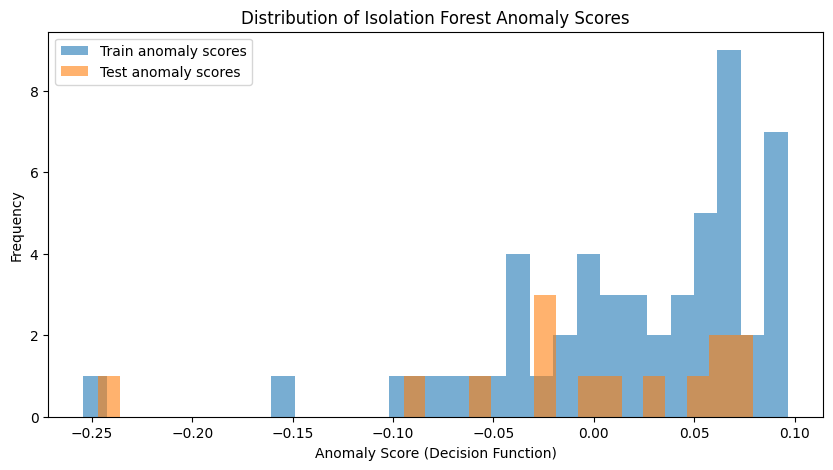

In [16]:
train_anomalies, test_anomalies, iso_forest = train_test_isolation_forest(X_train, X_test)
plot_train_test_anomaly_scores(iso_forest, X_train, X_test)

The histogram above compares the distribution of anomaly scores for the train and test sets as assigned by the Isolation Forest model. Both sets display a similar spread of scores, with most observations having positive anomaly scores (considered normal) and a few samples with negative scores (indicating potential anomalies).  
There is substantial overlap in the score distributions, suggesting that:
- The anomaly detection model treats train and test data similarly, with no major shift or bias introduced by the train-test split
- There is no evidence of data leakage or unexpected structural difference in anomaly scores between the train and test partitions
- The unsupervised anomaly detection process identifies outliers in a consistent way across both subsets, supporting the reliability of the model for flagging unusual records
- This similarity in anomaly score patterns between train and test data adds confidence to the validity of the modeling workflow and provides a solid foundation for further detailed anomaly analysis

#### 2.3.1 Isolation Forest on PCA-Reduced Data (2 Components)

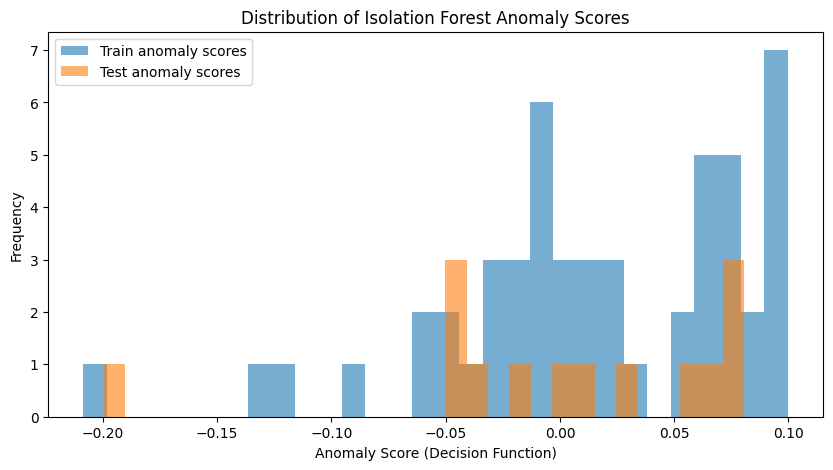

In [17]:
train_anomalies_pca2, test_anomalies_pca2, iso_forest_pca2 = train_test_isolation_forest(X_train = X_train_pca2, X_test = X_test_pca2)
plot_train_test_anomaly_scores(iso_forest_pca2, X_train_pca2, X_test_pca2)

Isolation Forest anomaly score distributions remain broadly similar before and after PCA reduction, indicating stable and consistent outlier detection. Minor shifts in score frequencies reflect the effects of dimensionality reduction, but key patterns and the separation between typical and anomalous enterprises are preserved, supporting the validity of using 2-component PCA for efficient anomaly detection.

### 2.4 Model IV: Shallow Neural Network<sup>6</sup>

Because the dataset is relatively small, a *shallow neural network* is appropriate to effectively learn patterns without overfitting. Instead of using true class labels (which are not available), the network will be trained using the cluster assignments from the K-means clustering model as surrogate labels. This approach enables a supervised learning framework that leverages the unsupervised segmentation discovered earlier, allowing the neural network to learn and potentially approximate the underlying cluster structure in a nonlinear way. This combined strategy helps gain deeper insights into the data and supports more robust classification of enterprise segments.

In [18]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

def train_test_nn(X_train, X_test, k_means_train_labels, k_means_test_labels):
    """
    Trains a shallow neural network classifier on training data using K-Means cluster labels as targets. 
    Predicts cluster labels on train and test sets.

    Parameters
    ----------
    X_train : numpy.ndarray
        Training feature data.
    X_test : numpy.ndarray
        Test feature data.
    k_means_train_labels : numpy.ndarray
        Cluster labels from K-Means used as surrogate target for training.
    k_means_test_labels : numpy.ndarray
        Cluster labels for test set used for evaluation.

    Returns
    -------
    nn_clf : sklearn.neural_network.MLPClassifier
        Trained neural network model.
    nn_train_pred : numpy.ndarray
        Predicted cluster labels on training data.
    nn_test_pred : numpy.ndarray
        Predicted cluster labels on test data.
    """
    
    # One hidden layer with at least as many neurons as features (8)
    nn_clf = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation='relu',
        solver='lbfgs',
        random_state=42
    )
    
    # Supervised by K-means clusters
    nn_clf.fit(X_train, k_means_train_labels)
    
    nn_train_pred = nn_clf.predict(X_train)
    nn_test_pred = nn_clf.predict(X_test)
    
    print("Train accuracy: ", accuracy_score(k_means_train_labels, nn_train_pred))
    print("Test accuracy: ", accuracy_score(k_means_test_labels, nn_test_pred))

    return nn_clf, nn_train_pred, nn_test_pred

nn_clf, nn_train_pred, nn_test_pred = train_test_nn(X_train, X_test, k_means_train_labels, k_means_test_labels)

Train accuracy:  1.0
Test accuracy:  1.0


K-means clustering divides the data into balanced, meaningful segments using feature similarity, and these cluster labels are used as surrogate targets for the neural network. The network achieves perfect accuracy on both train and test sets, fully replicating the clustering structure and efficiently classifying new enterprises. This supervised neural approach complements the unsupervised models, enabling robust, nonlinear group prediction and deeper analysis of enterprise variation.

"The default solver ‘adam’ works pretty well on relatively large datasets (with thousands of training samples or more) in terms of both training time and validation score. For small datasets, however, ‘lbfgs’ can converge faster and perform better." <sup>7</sup>

#### 2.3.1 Shallow Neural Network on PCA-Reduced Data (2 Components)

In [19]:
nn_clf_pca2, nn_train_pred_pca2, nn_test_pred_pca2 = train_test_nn(X_train_pca2, X_test_pca2, k_means_train_labels_pca2, k_means_test_labels_pca2)

Train accuracy:  1.0
Test accuracy:  1.0


Dimensionality reduction did not degrade performance.

## 3. Analysis

Present and analyse the results of the training above. 

### 3.1 Results

Present the performance of your models in a clear and succinct way.

This can be done manually (in markdown) or programmatically (storing results in a data structure during training runs and displaying its contents here).

#### PCA results

Number of PCA components retained: 4

Explained variance ratio per component:
  PC1: 0.7587
  PC2: 0.1696
  PC3: 0.0423
  PC4: 0.0237

Cumulative explained variance:
  PC1..PC1: 0.7587
  PC1..PC2: 0.9283
  PC1..PC3: 0.9706
  PC1..PC4: 0.9943


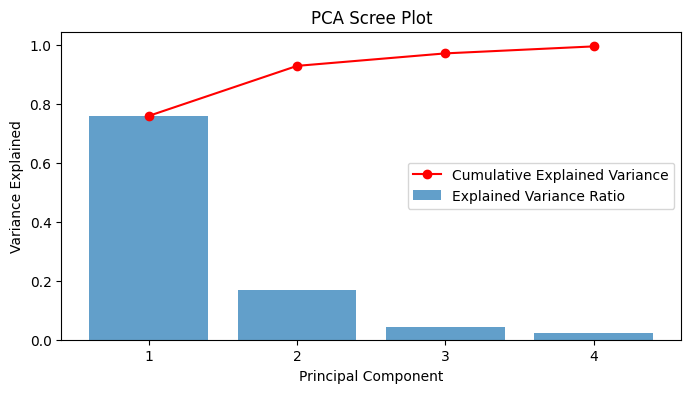

In [20]:
def describe_pca_variance(pca, X_train_pca, X_test_pca):
    """
    Prints and plots explained variance ratio by PCA components.
    (How much of the variance is explained by the components).

    Parameters
    ----------
    pca : sklearn.decomposition.PCA
        The fitted PCA model.
    X_train_pca : numpy.ndarray
        PCA transformed training data.
    X_test_pca : numpy.ndarray
        PCA transformed test data.

    Returns
    -------
    None
    """
    
    explained_var = pca.explained_variance_ratio_
    cumulative_var = np.cumsum(explained_var)

    print(f"Number of PCA components retained: {pca.n_components_}")
    print("\nExplained variance ratio per component:")
    for i, var_ratio in enumerate(explained_var):
        print(f"  PC{i+1}: {var_ratio:.4f}")
        
    print("\nCumulative explained variance:")
    for i, cum_var in enumerate(cumulative_var):
        print(f"  PC1..PC{i+1}: {cum_var:.4f}")

     # Plot it
    plt.figure(figsize=(8, 4))
    components = np.arange(1, pca.n_components_ + 1)
    plt.bar(components, explained_var, alpha=0.7, label='Explained Variance Ratio')
    plt.plot(components, cumulative_var, color='red', marker='o', label='Cumulative Explained Variance')
    plt.xlabel('Principal Component')
    plt.ylabel('Variance Explained')
    plt.title('PCA Scree Plot')
    plt.xticks(components)
    plt.legend()
    plt.show()

describe_pca_variance(pca, X_train_pca, X_test_pca)

- 4 PCs retained
- Cumulative variance: 99.43%
- Two main components: PC1: 75.9%, PC2: 17%.

#### K-means Clustering results

In [21]:
def describe_kmeans(kmeans, train_labels, test_labels):
    """
    Prints basic info on K-Means clustering including number of clusters and cluster sizes in train set.

    Parameters
    ----------
    kmeans : sklearn.cluster.KMeans
        Fitted K-Means model.
    train_labels : numpy.ndarray
        Cluster labels for training data.
    test_labels : numpy.ndarray
        Cluster labels for test data.

    Returns
    -------
    cluster_sizes : dict
        Dictionary of cluster id to number of samples in training set.
    """
    
    unique, counts = np.unique(k_means_train_labels, return_counts=True)
    cluster_sizes = dict(zip(unique, counts))
    print(f"Number of clusters: {kmeans.n_clusters}")
    print(f"Train cluster sizes: {cluster_sizes}")
    return cluster_sizes

In [22]:
_ = describe_kmeans(kmeans, k_means_train_labels, k_means_test_labels)

Number of clusters: 4
Train cluster sizes: {np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


- Number of clusters: 4
- Train cluster sizes: {0: 27, 1: 8, 2: 7, 3: 10}
- Cluster assignment performed on standardized train set using KMeans (random_state=42).
- Test set also predicted into clusters using the fitted model

##### K-means Clustering results on PCA-Reduced Data (2 Components)

In [23]:
_ = describe_kmeans(kmeans_pca2, k_means_train_labels_pca2, k_means_test_labels_pca2)

Number of clusters: 4
Train cluster sizes: {np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


The matching cluster sizes and assignments in the PCA-reduced feature space confirm that dimensionality reduction fully preserves the key segmentation structure. This not only supports effective clustering in a simplified setting, but also enhances the clarity and interpretability of subsequent analysis and business insights

#### Isolation Forest results

In [24]:
def describe_iso_forest(iso_forest, train_anomalies, test_anomalies):
    """
    Prints summary statistics about the anomalies detected by Isolation Forest in train and test data.

    Parameters
    ----------
    iso_forest : sklearn.ensemble.IsolationForest
        Fitted Isolation Forest model.
    train_anomalies : numpy.ndarray
        Anomaly prediction labels on training data (-1 or 1).
    test_anomalies : numpy.ndarray
        Anomaly prediction labels on test data (-1 or 1).

    Returns
    -------
    None
    """
    
    train_anomaly_count = np.sum(train_anomalies == -1)
    test_anomaly_count = np.sum(test_anomalies == -1)
    
    # Print results summary
    print(f" - Number of train samples: {len(train_anomalies)}")
    print(f" - Number of anomalies detected in train: {train_anomaly_count}")
    print(f" - Number of test samples: {len(test_anomalies)}")
    print(f" - Number of anomalies detected in test: {test_anomaly_count}")
    print(f" - Anomaly proportion (train): {train_anomaly_count/len(train_anomalies):.3f}")
    print(f" - Anomaly proportion (test): {test_anomaly_count/len(test_anomalies):.3f}")

In [25]:
describe_iso_forest(iso_forest, train_anomalies, test_anomalies)

 - Number of train samples: 52
 - Number of anomalies detected in train: 17
 - Number of test samples: 14
 - Number of anomalies detected in test: 7
 - Anomaly proportion (train): 0.327
 - Anomaly proportion (test): 0.500


The Isolation Forest model was trained on the standardized training data with default parameters, including 100 trees (n_estimators=100) and automatically estimated contamination (contamination='auto'), allowing the model to determine the anomaly threshold adaptively.

The model labeled samples as anomalies (-1) or normal (1), detecting:
- Train data: 17 anomalies out of 52 samples (~32.7% anomaly proportion)
- Test data: 7 anomalies out of 14 samples (50% anomaly proportion)

This higher anomaly proportion suggests the model is sensitive to unusual patterns in the data.

##### Isolation Forest results on PCA-Reduced Data (2 Components)

In [26]:
describe_iso_forest(iso_forest_pca2, train_anomalies_pca2, test_anomalies_pca2)

 - Number of train samples: 52
 - Number of anomalies detected in train: 24
 - Number of test samples: 14
 - Number of anomalies detected in test: 6
 - Anomaly proportion (train): 0.462
 - Anomaly proportion (test): 0.429


Although the number and proportion of anomalies detected by Isolation Forest differ somewhat between the original and PCA-reduced data, the core structural outlier patterns remain largely preserved. The increased anomaly detection in the PCA space indicates that dimensionality reduction can subtly affect sensitivity to unusual patterns, but Isolation Forest continues to provide a reliable and informative tool for anomaly detection and risk assessment in both full and simplified feature spaces. This highlights the resilience of the method alongside the principal components in capturing enterprise exceptions effectively.

#### Shallow Neural Network results

In [27]:
from sklearn.metrics import classification_report, confusion_matrix

def describe_nn(nn, train_labels, test_labels, train_pred, test_pred):
    """
    Prints accuracy, confusion matrix, and classification report for neural network predictions on train and test sets.

    Parameters
    ----------
    nn : sklearn.neural_network.MLPClassifier
        Trained neural network model.
    train_labels : numpy.ndarray
        True cluster labels for training data.
    test_labels : numpy.ndarray
        True cluster labels for test data.
    train_pred : numpy.ndarray
        Predicted cluster labels from NN for training data.
    test_pred : numpy.ndarray
        Predicted cluster labels from NN for test data.

    Returns
    -------
    None
    """
    
    print(f"Train accuracy: {accuracy_score(train_labels, train_pred):.2f}")
    print(f"Test accuracy: {accuracy_score(test_labels, test_pred):.2f}")
    
    print("Train confusion matrix:")
    print(confusion_matrix(train_labels, train_pred))
    
    print("Test confusion matrix:")
    print(confusion_matrix(test_labels, test_pred))
    
    print("Train classification report:")
    print(classification_report(train_labels, train_pred))
    
    print("Test classification report:")
    print(classification_report(test_labels, test_pred))

describe_nn(nn_clf, k_means_train_labels, k_means_test_labels, nn_train_pred, nn_test_pred)

Train accuracy: 1.00
Test accuracy: 1.00
Train confusion matrix:
[[27  0  0  0]
 [ 0  8  0  0]
 [ 0  0  7  0]
 [ 0  0  0 10]]
Test confusion matrix:
[[6 0 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 1]]
Train classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00        10

    accuracy                           1.00        52
   macro avg       1.00      1.00      1.00        52
weighted avg       1.00      1.00      1.00        52

Test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1

    accuracy                           1.0

- The neural network achieved perfect accuracy (1.0) on both training and test sets
- The confusion matrices show every sample was assigned to the correct cluster, with no misclassifications
- The classification reports confirm that precision, recall, and f1-score are all 1.00 for every cluster, demonstrating consistency across all segments
- The relatively balanced cluster sizes (as indicated in the support column) ensure fair representation in learning and evaluation

##### Shallow Neural Network results on PCA-Reduced Data (2 Components)

In [28]:
describe_nn(nn = nn_clf_pca2, train_labels = k_means_train_labels_pca2, test_labels = k_means_test_labels_pca2, train_pred = nn_train_pred_pca2, test_pred = nn_test_pred_pca2)

Train accuracy: 1.00
Test accuracy: 1.00
Train confusion matrix:
[[27  0  0  0]
 [ 0  8  0  0]
 [ 0  0  7  0]
 [ 0  0  0 10]]
Test confusion matrix:
[[6 0 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 1]]
Train classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00        10

    accuracy                           1.00        52
   macro avg       1.00      1.00      1.00        52
weighted avg       1.00      1.00      1.00        52

Test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1

    accuracy                           1.0

Consistent results across neural network runs on the original and PCA-reduced data validate both the segmentation and modeling choices, demonstrating a stable and interpretable market structure.

### 3.2 Analysis & Comparison

Analyse your results. This should include:

- Succinctly summarising the strengths and weaknesses, as well as potential problems, and their remedies, of the model classes you used, as seen in the course.
- Comparing the performance of the models you trained: accuracy is obviously the key metric to watch in most cases, but other factors can also play a role (such as computational cost, for instance: what if a complex model, that takes hours to train, only beats a much simpler and faster one by only a small margin?).
- Assess how each model is suited to the chosen dataset, and which model(s) is (are) the best.

You are free to organise this section as you see fit, depending on the requirements of your experiments. However, it is recommended to take extra care to make it clean and orderly, subdivising it into sections using markdown headings, for better readability. Feel free to use plots if relevant.

#### PCA analysis

Number of PCA components retained: 4

Explained variance ratio per component:
  PC1: 0.7587
  PC2: 0.1696
  PC3: 0.0423
  PC4: 0.0237

Cumulative explained variance:
  PC1..PC1: 0.7587
  PC1..PC2: 0.9283
  PC1..PC3: 0.9706
  PC1..PC4: 0.9943


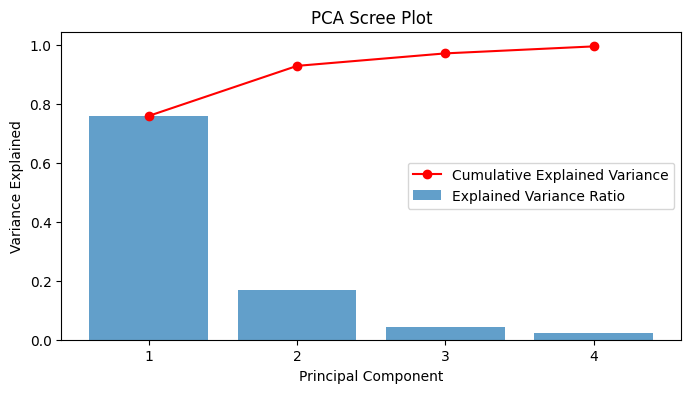


Top 5 loadings per principal component (absolute value):
  PC1 top contributing features: ['Value added (million HUF)', 'Net Sales Revenue (million HUF)', 'National economic investment (million HUF)', 'Export Sales Revenue (million HUF)', 'Revenue per Employee (thousand HUF/person)']
  PC2 top contributing features: ['Number of Enterprises', 'Number of Employees', 'Employee Distribution (%)', 'Revenue per Employee (thousand HUF/person)', 'National economic investment (million HUF)']
  PC3 top contributing features: ['Number of Enterprises', 'Employee Distribution (%)', 'Number of Employees', 'Export Sales Revenue (million HUF)', 'National economic investment (million HUF)']
  PC4 top contributing features: ['Revenue per Employee (thousand HUF/person)', 'Export Sales Revenue (million HUF)', 'Number of Enterprises', 'National economic investment (million HUF)', 'Employee Distribution (%)']


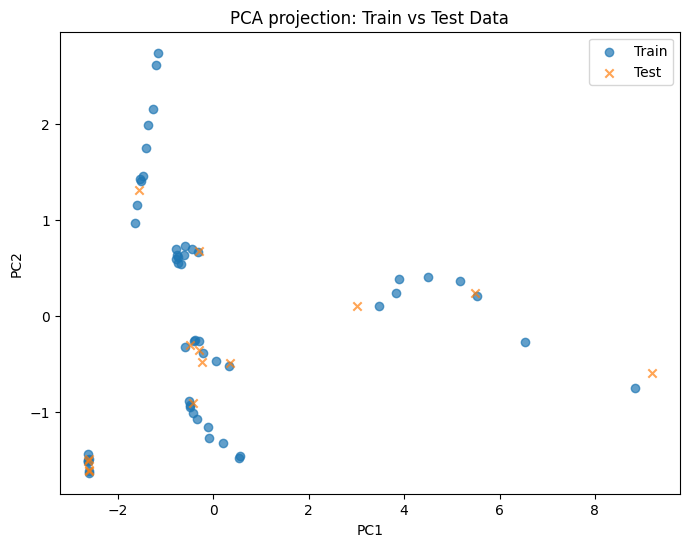

In [29]:
def describe_pca_var_and_features(pca, X_train_pca, X_test_pca):
    """
    Provides a detailed summary and visualization of PCA results, including explained variance and 
    principal component feature loadings, and compares train and test data distributions in PCA space.

    This function prints the explained variance ratios per principal component and lists the top contributing 
    features (by absolute loading values) for the first three principal components. It also produces a scatter 
    plot showing the distribution of training and test samples projected onto the first two principal components 
    for visual comparison of data representation.

    Parameters
    ----------
    pca : sklearn.decomposition.PCA
        The fitted PCA model.

    X_train_pca : numpy.ndarray
        PCA-transformed training data.

    X_test_pca : numpy.ndarray
        PCA-transformed test data.

    Returns
    -------
    None
        Outputs are printed summary statistics and a matplotlib scatter plot comparing train and test PCA projections.
    """
    
    describe_pca_variance(pca=pca, X_train_pca=X_train_pca, X_test_pca=X_test_pca)

    # Feature summary
    features = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(pca.n_components_)], index=indicators)
    print("\nTop 5 loadings per principal component (absolute value):")
    for i in range(min(5, pca.n_components_)):
        pc_loadings = features.iloc[:, i].abs().sort_values(ascending=False)
        top_features = pc_loadings.head(5).index.tolist()
        print(f"  PC{i+1} top contributing features: {top_features}")

    # Scatter plot of PC1 and PC2 for train and test
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], label='Train', alpha=0.7)
    plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], label='Test', alpha=0.7, marker='x')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA projection: Train vs Test Data')
    plt.legend()
    plt.show()

describe_pca_var_and_features(pca, X_train_pca, X_test_pca)

The PCA reduced the dataset to four principal components, capturing 99.43% of the total variance. The first principal component (PC1) alone explains nearly 76%, with the second component (PC2) adding another 17%. This significant variance capture validates the effectiveness of dimensionality reduction for summarizing the dataset.

PC1 broadly integrates multiple financial and structural indicators - highlighting a composite axis of overall economic health and scale. Specifically, PC1 is most strongly influenced by:
- Value added
- Net sales revenue
- National economic investment
- Export sales revenue
- Revenue per employee

While these financial indicators dominate PC1, subsequent analysis will reveal the important role of structural metrics.

In contrast, PC2 is dominated by structural and categorical metrics, including:
- number of enterprises
- number of employees
- employee distribution
- investment  

PC2 thus captures the organizational structure and workforce characteristics that differentiate SME segments.

Subsequent components (PC3 and beyond) contribute only minor variation, serving mainly to refine distinctions established by PC1 and PC2.

The scatter plot of the first two principal components shows that both train and test sets have similar spread and overlap in the PCA-transformed space. This confirms that the split was done appropriately, maintaining the original data structure without introducing bias or leakage. There is no strong separation between the groups, suggesting consistent company behavior and indicator relationships across years and size classes.

- **Strengths:** PCA allows for both information-rich visualization and feature reduction, making subsequent modeling (clustering, anomaly detection) more efficient and interpretable
- **Weaknesses:** Interpretability of later components may decrease; nonlinear patterns (if present) are not captured

**Conclusion:** PCA is highly effective on this enterprise development dataset: it captures the majority of variation in a small number of dimensions that can be clearly tied to economic meaning. Its clear, intuitive output strongly supports further unsupervised learning and in-depth business indicator analyses.

##### PCA analysis using 2 components

The main PCA characteristics described earlier still apply here; we simply limit the analysis to the first two components, omitting the third and fourth.  
This section focuses on linking these two principal components directly to underlying business indicators for clearer economic interpretation.

In [30]:
def plot_pca_loadings_with_contribution(pca):
    """
    Shows how original economic indicators contribute to the components.
    This plot bridges PCA dimensions back to meaningful business variables, enhancing interpretability of anomaly locations.
    Bar plot of PCA loadings with contribution % annotations per feature for PC1 and PC2.

    Parameters
    ----------
    pca : sklearn.decomposition.PCA
        The fitted PCA model.

    Returns
    -------
    None
        Displays a matplotlib bar plot.
    """
   
    loadings = pca.components_.T
    n_features = len(indicators)
    indices = np.arange(n_features)
    width = 0.35

    # Calculate % contribution scaled by explained variance
    explained_var = pca.explained_variance_ratio_[:2]
    contrib_pc1 = (np.abs(loadings[:, 0]) * explained_var[0]) / np.sum(np.abs(loadings[:, 0]) * explained_var[0]) * 100
    contrib_pc2 = (np.abs(loadings[:, 1]) * explained_var[1]) / np.sum(np.abs(loadings[:, 1]) * explained_var[1]) * 100

    plt.figure(figsize=(12,6))
    bars1 = plt.bar(indices - width/2, loadings[:, 0], width, label='PC1')
    bars2 = plt.bar(indices + width/2, loadings[:, 1], width, label='PC2')
    
    plt.xticks(indices, indicators, rotation=45, ha='right')
    plt.ylabel('PCA Loading')
    plt.title('Feature Loadings for First Two PCA Components (with contribution %)')

    # Annotate percentage contributions
    for i, (bar, c) in enumerate(zip(bars1, contrib_pc1)):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{c:.1f}%', ha='center', va='bottom', fontsize=8, rotation=90)
    for i, (bar, c) in enumerate(zip(bars2, contrib_pc2)):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'{c:.1f}%', ha='center', va='bottom', fontsize=8, rotation=90)
    plt.legend()
    plt.show()


def plot_top_loadings(pca, n=4, figsize = (7, 5), only_pca = None, category = None):
    """
    Plots the top positive and negative feature loadings for specified PCA components to aid interpretability.

    Since there are 8 indicators in total, selecting n=4 shows the top 4 positive and bottom 4 negative loadings 
    for a principal component, fully covering all 8 indicators and illustrating their contributions to that component.

    Parameters
    ----------
    pca : sklearn.decomposition.PCA
        The fitted PCA model.
    n : int, optional
        Number of top positive and negative loadings to show (default is 4).
    figsize : tuple, optional
        Figure size for the plot (default is (7, 5)).
    only_pca : int or None, optional
        If specified, plots loadings only for this PCA component (1-based index). Otherwise, plots all components.
    category : str or None, optional
        Optional category label added to the plot title for contextual interpretation.

    Returns
    -------
    None
        Displays horizontal bar plots of feature loadings per PCA component.
    """

    if type(only_pca) is int:
        comp = pca.components_[only_pca - 1, :]
        loadings = pd.DataFrame(comp.reshape(-1, 1), index=indicators, columns=[f'PC{only_pca}'])
    else:
        loadings = pd.DataFrame(pca.components_.T, index=indicators,
                            columns=[f'PC{i+1}' for i in range(pca.n_components_)])

    for pc in loadings.columns:
        sorted_loadings = loadings[pc].sort_values()
        top_features = pd.concat([sorted_loadings.head(n), sorted_loadings.tail(n)])
        plt.figure(figsize=figsize)
        colors = ['red' if val < 0 else 'blue' for val in top_features]
        top_features.plot(kind='barh', color=colors)
        plt.title(f'Top ±{n} Feature Loadings for {pc} {"in category " + category if category else ""}')
        plt.xlabel('Loading Value')
        plt.ylabel('Feature')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.show()

def plot_pca_biplot_top_n(pca, X_pca, pc_x=0, pc_y=1, scale=2, n=5):
    """
    Creates a PCA biplot combining sample scores and the top loading vectors for specified components to aid interpretation.

    This plot visualizes the data points projected onto two principal components along with arrows representing 
    the directions and magnitudes of the top contributing features. It helps interpret the relationship between 
    samples and original variables in the reduced PCA space.

    Parameters
    ----------
    pca : sklearn.decomposition.PCA
        The PCA model fitted on the dataset.
    X_pca : numpy.ndarray
        Data transformed into PCA space, shape (samples, components).
    pc_x : int, optional
        Index of the principal component for the x-axis (default 0 for PC1).
    pc_y : int, optional
        Index of the principal component for the y-axis (default 1 for PC2).
    scale : float, optional
        Scaling factor for the feature loading vectors (default 2).
    n : int, optional
        Number of top features (by absolute loading sum) to display (default 5).

    Returns
    -------
    None
        Displays a scatter plot with loading arrows and prints the top feature names.
    """
    plt.figure(figsize=(10,8))
    xs = X_pca[:, pc_x]
    ys = X_pca[:, pc_y]
    plt.scatter(xs, ys, alpha=0.7, edgecolors='k', label='Samples')

    abs_loadings = np.abs(pca.components_[[pc_x, pc_y], :]).sum(axis=0)
    top_idx = np.argsort(abs_loadings)[-n:]

    print("-- Top features --")
    for i in top_idx:
        plt.arrow(0, 0, pca.components_[pc_x, i]*scale, pca.components_[pc_y, i]*scale,
                  color='r', alpha=0.8, head_width=0.08, head_length=0.08, length_includes_head=True)
        plt.text(pca.components_[pc_x, i]*scale*1.25, pca.components_[pc_y, i]*scale*1.25,
                 indicators[i], color='r', fontsize=12, weight='bold')
        print(indicators[i])

    plt.xlabel(f'PC{pc_x+1} ({pca.explained_variance_ratio_[pc_x]*100:.1f}% variance)')
    plt.ylabel(f'PC{pc_y+1} ({pca.explained_variance_ratio_[pc_y]*100:.1f}% variance)')
    plt.title('PCA Biplot (samples + top feature loadings)')
    plt.grid()
    plt.legend()
    plt.axhline(0, color='grey', linewidth=0.5)
    plt.axvline(0, color='grey', linewidth=0.5)
    plt.tight_layout()
    plt.show()

In [31]:
# Plot used for business analysis in chapter 4
def feature_contribution_per_size_categories(n_components = 2):
    """
    Performs PCA separately for each company size category and plots the top feature loadings for the first principal component.

    This function standardizes the features for each company size category, fits PCA with a specified number of components,
    and then visualizes the top positive and negative loadings of the first principal component. The plots help interpret 
    how original economic indicators contribute differently across SME size categories.

    Parameters
    ----------
    n_components : int, optional
        Number of principal components to compute for each category (default is 2).

    Returns
    -------
    None
        Displays bar plots of top feature loadings per size category.
    """
    
    category_pcas = {}
    for category in wide_df['Company Size Category'].unique():
        df_cat = wide_df[wide_df['Company Size Category'] == category]
        X = df_cat[indicators].values
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        pca = PCA(n_components = n_components, random_state=42)
        pca.fit(X_scaled)
        
        category_pcas[category] = pca
    
    for category, pca_obj in category_pcas.items():
        plot_top_loadings(pca_obj, n=3, figsize=(1,2), only_pca=1, category=category)

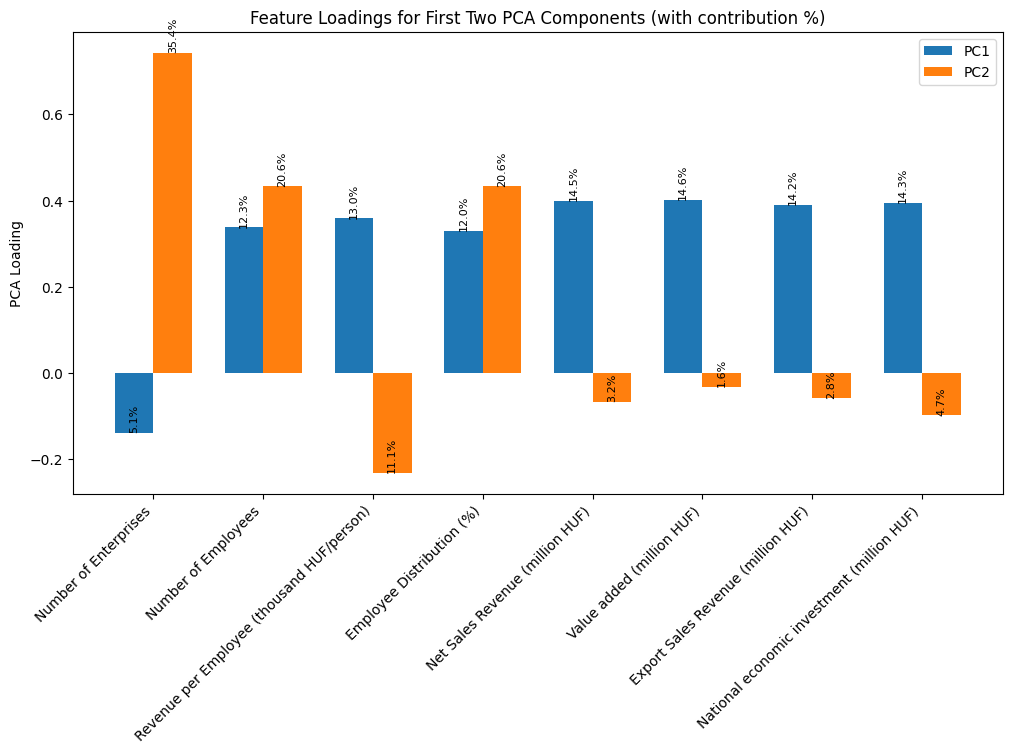

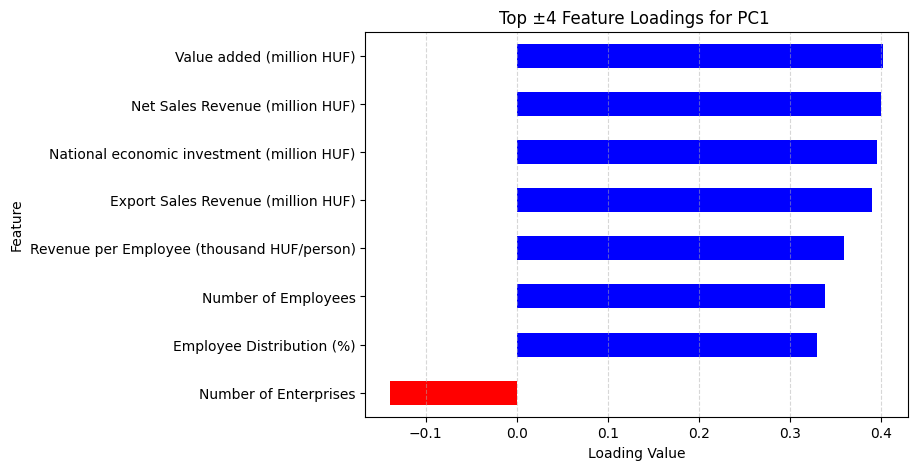

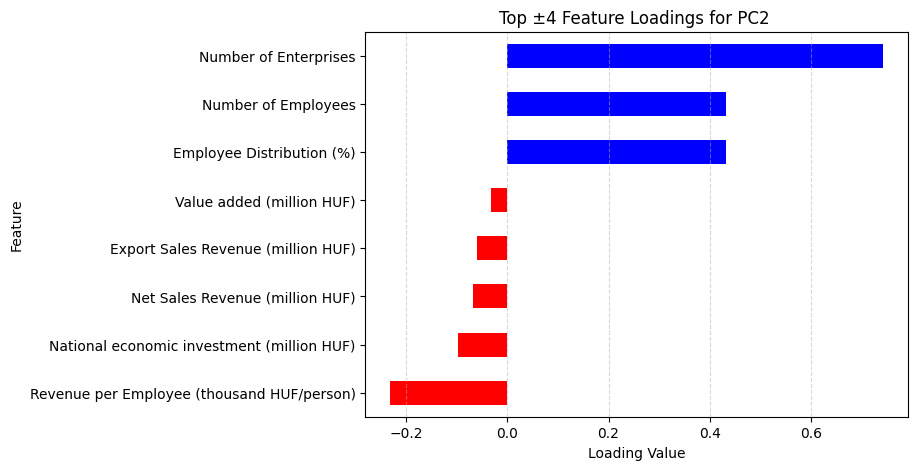

-- Top features --
National economic investment (million HUF)
Revenue per Employee (thousand HUF/person)
Employee Distribution (%)
Number of Employees
Number of Enterprises


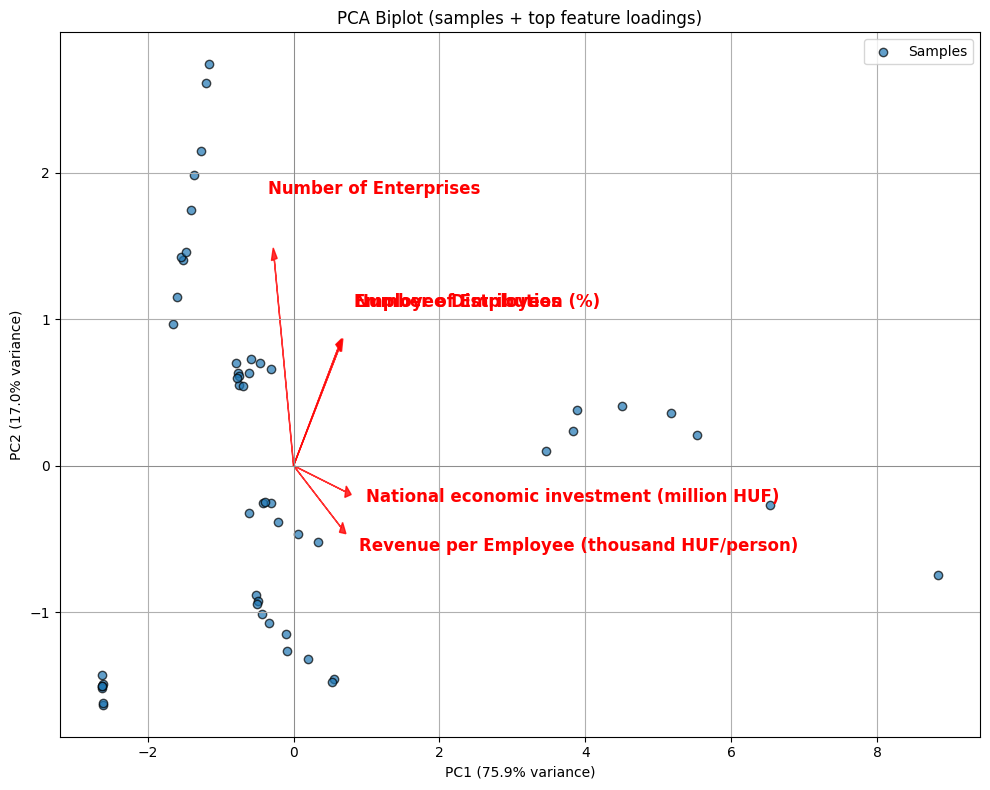

In [32]:
plot_pca_loadings_with_contribution(pca2)
plot_top_loadings(pca2)
plot_pca_biplot_top_n(pca2, X_train_pca2)

The PCA decomposition focusing on two principal components preserves the essential economic structure of the SME dataset. The bar plots of component loadings and contribution percentages show that PC1 is driven by a broad mix of both financial indicators (such as value added, net sales revenue, export sales revenue, and national economic investment) and structural metrics (like number of employees and employee distribution) - highlighting that the main axis of variance blends both company output and workforce scale. Notably, "number of enterprises" contributes negatively to PC1, marking a distinction in segment definitions.

PC2 is dominated by organizational structure variables - number of enterprises, number of employees, and employee distribution - with additional negative contributions from some financial indicators. This shows that PC2 primarily captures differences in business structure, segregating groups by organizational characteristics.

The top loadings plots clarify the positive and negative direction of each indicator for both components, while the biplot visually maps sample positions and links them to the most influential business indicators. Together, these visuals illustrate how SME group characteristics project onto underlying economic and structural dimensions in a reduced feature space.

These results confirm that, even with only two principal components, PCA effectively distills SME patterns and relationships along interpretable axes - providing a robust and evidence-backed foundation for further business modeling, benchmarking, and anomaly detection in subsequent analyses.

#### K-means Clustering analysis

Number of clusters: 4
Train cluster sizes: {np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


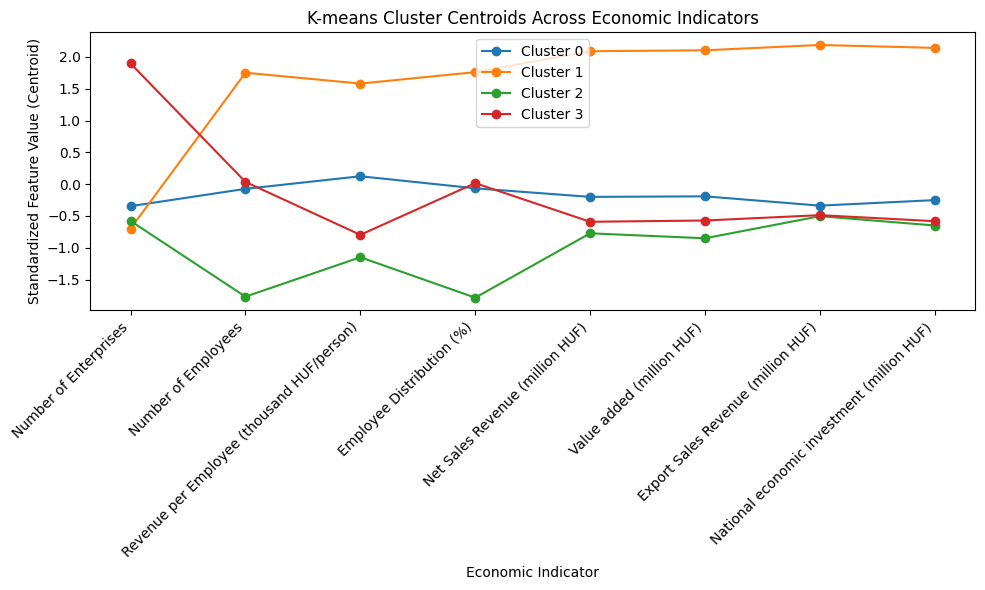

Silhouette score: 0.606


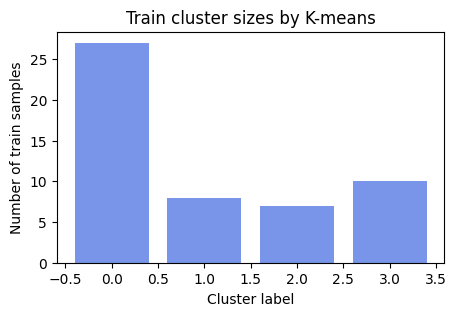

In [33]:
from sklearn.metrics import silhouette_score

def describe_kmeans_detailed(kmeans, train_labels, test_labels, indicators):
    """
    Provides a detailed summary and visualization of K-means clustering results.

    This function:
    - Prints cluster sizes using a helper function.
    - Plots the centroids of clusters as average standardized feature values per economic indicator.
    - Calculates and prints the silhouette score to quantify cluster separation quality.
    - Displays a bar chart showing the distribution of training samples across clusters.

    Parameters
    ----------
    kmeans : sklearn.cluster.KMeans
        The fitted K-means clustering model.
    train_labels : numpy.ndarray
        Cluster labels for the training dataset.
    test_labels : numpy.ndarray
        Cluster labels for the test dataset.
    indicators : list of str
        List of feature names corresponding to the columns used in clustering.

    Returns
    -------
    None
        Outputs printed metrics and matplotlib plots.
    """
    
    cluster_sizes = describe_kmeans(kmeans, k_means_train_labels, k_means_test_labels)

    # Show centroids (feature averages per cluster)
    centroids = pd.DataFrame(kmeans.cluster_centers_, columns=indicators)

    plt.figure(figsize=(10,6))
    for i, row in centroids.iterrows():
        plt.plot(indicators, row, marker='o', label=f'Cluster {i}')
    plt.xticks(rotation=45, ha='right')
    plt.xlabel('Economic Indicator')
    plt.ylabel('Standardized Feature Value (Centroid)')
    plt.title('K-means Cluster Centroids Across Economic Indicators')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Silhouette score (higher is better)
    score = silhouette_score(X_train, k_means_train_labels)
    print(f"Silhouette score: {score:.3f}")

    # Plot cluster sizes
    plt.figure(figsize=(5,3))
    plt.bar(cluster_sizes.keys(), cluster_sizes.values(), color='royalblue', alpha=0.7)
    plt.xlabel('Cluster label')
    plt.ylabel('Number of train samples')
    plt.title('Train cluster sizes by K-means')
    plt.show()

describe_kmeans_detailed(kmeans, k_means_train_labels, k_means_test_labels, indicators)

**Strengths**
- Uncovers natural groups: The K-means algorithm effectively partitions enterprises into four clusters based on similar economic characteristics, as visualized in the centroid plot. Each group demonstrates distinct profiles across key performance indicators (e.g., net sales revenue, employee numbers), helping to reveal dominant regimes in the Hungarian enterprise sector
- Interpretability: Every sample is assigned a clear cluster label, which facilitates subsequent group-based analysis and visualization. The centroid plot vividly displays how clusters diverge on standardized indicator values
- Computationally efficient: K-means runs quickly and produced stable results, with reasonable silhouette score (0.606) indicating moderate cluster separation despite the small sample size

**Weaknesses and Potential Problems**
- Assumes spherical clusters: Real-world data may contain more complex patterns; K-means' geometric assumptions may oversimplify these relationships
- Requires 'k' selection: The user must pre-define the number of clusters, which may involve trial-and-error or model selection techniques
- Sensitive to scaling and initialization: The model's results depend upon appropriate standardization and initial random seed. Multiple initializations may be beneficial for greater robustness

**Distribution and Comparative Insight**
- The cluster sizes - illustrated in the bar chart - show that the data is segmented without extreme imbalance (27, 8, 7, 10 samples per cluster), supporting the existence of meaningful groups rather than arbitrary splits
- The centroid plot lays out differences in economic indicator profiles across clusters, and these results complement PCA’s principal component analysis by quantifying group variation on actual business indicators


**Dataset Fit and Conclusion**
K-means is well-suited for a multi-indicator, structure-seeking task such as enterprise classification. It exposes valuable groupings in company performance, which are potentially relevant for strategy, policy, or development interventions.
Overall, K-means clustering translates complex business data into interpretable group structures, offering critical insights into economic regimes in the Hungarian SME landscape. The model’s speed and transparency make it a strong companion to PCA and other unsupervised learning techniques for exploratory analytics.

##### K-means Clustering analysis on PCA-Reduced Data (2 Components)

After applying PCA, the original indicators are mathematically combined into new features called principal components (PC1, PC2). These components do not retain the original indicator names because each PC is a weighted linear combination of all original features.

Number of clusters: 4
Train cluster sizes: {np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


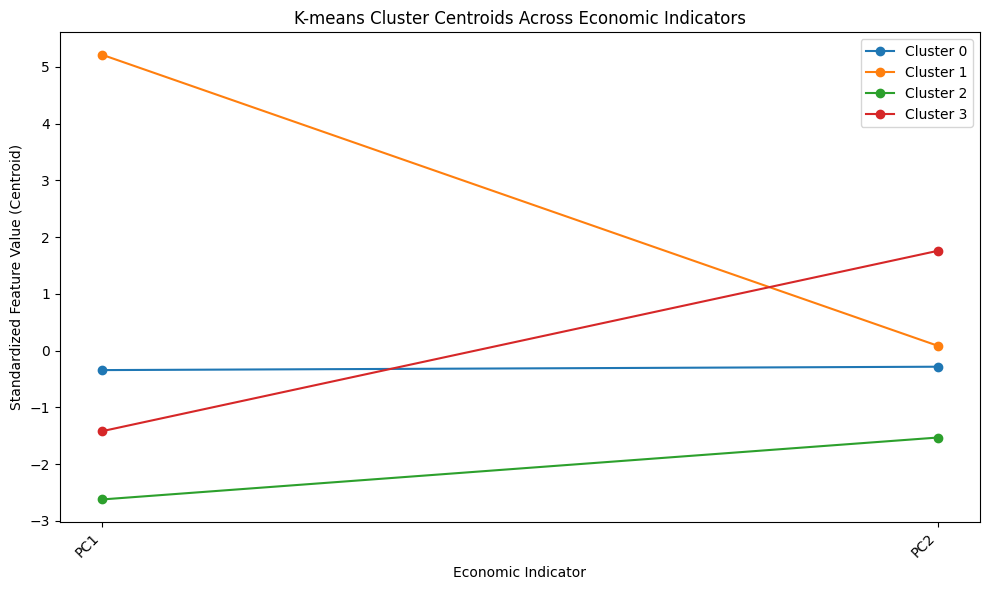

Silhouette score: 0.606


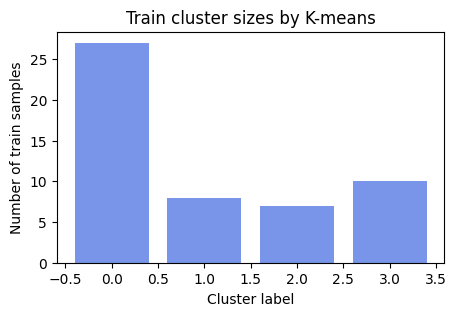

In [34]:
# Compare results with the non-PCA run K-means
pca_indicators = ['PC1', 'PC2']
describe_kmeans_detailed(kmeans=kmeans_pca2, train_labels = k_means_train_labels_pca2, test_labels = k_means_test_labels_pca2, indicators = pca_indicators)

There is a high structural stability and segmentation fidelity when transitioning from the original economic indicator space to the PCA-reduced space. This robustness highlights that detailed indicator-level insights are best examined using the original features, while PCA enables clear visualization and communication of broader, high-level groupings. Together, these complementary approaches enhance exploratory analysis and support more effective business decision-making.

In [35]:
from sklearn.metrics import silhouette_samples, silhouette_score

def k_means_clusters_in_pca_space():
    """
    Visualizes K-means cluster assignments in the two-dimensional PCA-reduced feature space for the training set.

    This scatter plot provides an intuitive and interpretable visual check of how well clusters are separated after dimensionality reduction.
    It helps assess cluster compactness and shape, indicating if clusters approximate spherical forms preferred by K-means.

    Parameters
    ----------
    None

    Returns
    -------
    None
        Displays a matplotlib scatter plot of the training samples colored by their K-means cluster assignments.
    """
    
    plt.figure(figsize=(7,5))
    scatter = plt.scatter(
        X_train_pca[:,0], X_train_pca[:,1], 
        c = k_means_train_labels_pca2, 
        cmap='tab10', s=80, alpha=0.8, edgecolors='k'
    )
    
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('K-means Cluster Assignments in PCA Space (Train Set)')
    plt.legend(*scatter.legend_elements(), title="Cluster")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

def k_means_cluster_centres_in_pca_space():
    """
    Plots K-means cluster centroids along with cluster assignments in the PCA-reduced feature space for training data.

    This visualization illustrates the geometric layout of cluster centers and how training samples are distributed 
    around these centroids in the two-dimensional PCA space. It clarifies cluster separation and proximity of points 
    to their corresponding cluster centers.

    Parameters
    ----------
    None

    Returns
    -------
    None
        Displays a scatter plot showing training samples colored by cluster with centroids marked distinctly.
    """
    
    centroids_pca = kmeans_pca2.cluster_centers_
    plt.figure(figsize=(7,5))
    plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=k_means_train_labels_pca2, cmap='tab10', alpha=0.8, s=70, label='Samples')
    plt.scatter(centroids_pca[:,0], centroids_pca[:,1], c='black', s=200, marker='X', label='Centroids')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('K-means Cluster Centroids and Assignments in PCA Space')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

def k_means_silhouette():
    """
    Plots the silhouette values for K-means clusters in PCA space to assess cluster separation quality.

    This silhouette plot quantifies how similar each sample is to its own cluster compared to other clusters,
    providing a rigorous complement to visual scatter plots. Higher silhouette values indicate better separated clusters,
    while lower or negative values indicate potential overlap or misclassification.

    Parameters
    ----------
    None

    Returns
    -------
    None
        Displays a horizontal bar silhouette plot with an overall silhouette score marked by a vertical line.
    """

    silhouette_vals = silhouette_samples(X_train_pca, k_means_train_labels_pca2)
    y_ticks = []
    
    plt.figure(figsize=(6,4))
    for i in np.unique(k_means_train_labels_pca2):
        cluster_silhouette_vals = silhouette_vals[k_means_train_labels_pca2 == i]
        cluster_silhouette_vals.sort()
        plt.barh(range(len(cluster_silhouette_vals)), cluster_silhouette_vals, height=1.0, edgecolor='none')
        y_ticks.append(len(cluster_silhouette_vals) // 2)
    plt.xlabel('Silhouette value')
    plt.ylabel('Cluster')
    plt.title('Silhouette Plot for K-means in PCA Space')
    plt.axvline(silhouette_score(X_train_pca, k_means_train_labels_pca2), color="red", linestyle="--")
    plt.tight_layout()
    plt.show()


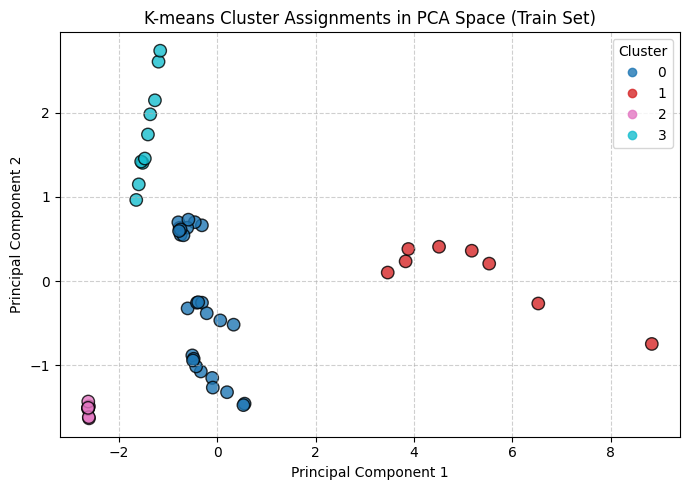

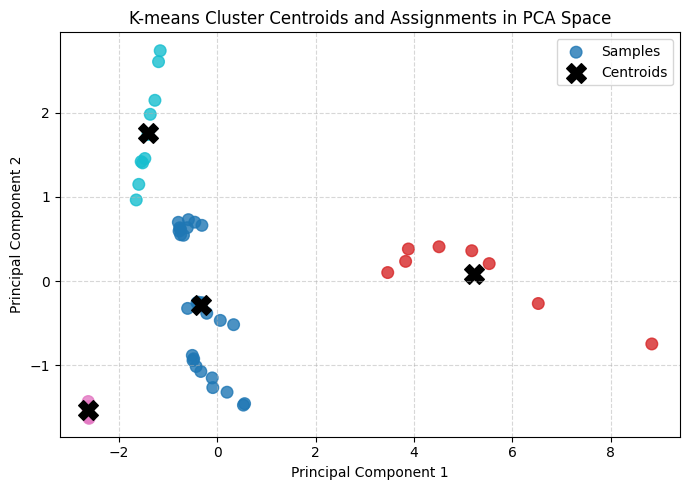

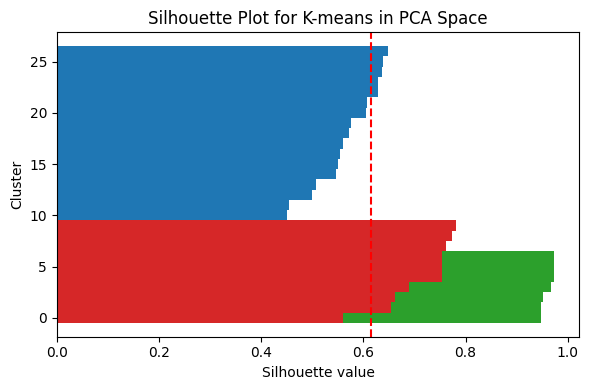

In [36]:
k_means_clusters_in_pca_space()
k_means_cluster_centres_in_pca_space()
k_means_silhouette()

The application of K-means clustering to the PCA-reduced dataset provides a clear, interpretable view of enterprise segmentation in Hungarian SMEs.

**Visual Structure and Cluster Separation**
- The scatter plot of cluster assignments in PCA space shows that the four clusters are clearly separated along the first two principal components. This demonstrates that the main axes of variance in the data correspond directly to meaningful business groupings.
- The centroids plot further highlights the geometric layout of the clusters. Cluster centers are well-distanced from each other in the PCA space, indicating that the segmentation is driven by strong, underlying factors reflected in just two dimensions
- Such separation in dimensionality-reduced space suggests that dominant economic indicators (as captured by PCA) are sufficient to distinguish enterprise regimes, enforcing the utility of dimensionality reduction before clustering

**Cluster Quality**
- The silhouette plot quantifies clustering performance, with most points exhibiting silhouette values well above 0.6. This suggests robust intra-cluster cohesion and inter-cluster separation, even after reducing the feature space
- The average silhouette score (marked in red) aligns with the earlier non-PCA results, indicating that clustering quality is preserved by PCA
- Few outliers in silhouette values suggest that most enterprises are confidently assigned to a segment, further validating K-means' effectiveness post-PCA

**Insights and Business Implications**
- Dimensionality reduction with PCA not only simplifies the data structure but also clarifies the boundaries between groups, making business insights more actionable
- Clusters distinguished in the PCA space can be directly related to blended economic dimensions (e.g., company size and revenue) instead of being lost in high-dimensional noise
- The interpretability of these results supports targeted policy interventions and strategic business decisions focused on the primary factors underlying SME development

**Comparative Strengths**
- Compared to clustering in the original feature space, clustering in PCA space retains group structure with improved clarity and computational efficiency
- The preserved cluster sizes and silhouette scores indicate no loss in segmentation quality, making PCA a valuable preprocessing step for exploratory and practical analytics
- Enhanced visual separability facilitates communication of insights to non-technical stakeholders

**Limitations and Considerations**
- While PCA simplifies analysis and aids visualization, some subtle indicator-level information may be blended or omitted; this must be considered in future, more granular investigations
- The inherently linear nature of PCA means complex non-linear patterns may not be fully captured, although this appears sufficient for the current dataset and business application

**Conclusion:**
K-means clustering in two-dimensional PCA space exposes the core structure of Hungarian SME performance data, enabling rapid, interpretable, and actionable enterprise segmentation. This validates PCA as a robust aid to unsupervised group discovery and complements the use of centroid, silhouette, and scatter plots for both technical and business-oriented analysis.

#### Isolation Forest analysis

In [37]:
def anomaly_counts_bar_plot(train_anomalies, test_anomalies):
    """
    Generates a bar plot showing the number of anomalies detected by the Isolation Forest in training and test datasets.

    Parameters
    ----------
    train_anomalies : numpy.ndarray
        Array of anomaly labels for the training set (-1 for anomaly, 1 for normal).
    test_anomalies : numpy.ndarray
        Array of anomaly labels for the test set (-1 for anomaly, 1 for normal).

    Returns
    -------
    None
        Displays a bar plot comparing the count of detected anomalies in train and test data.
    """
    
    train_anomaly_count = np.sum(train_anomalies == -1)
    test_anomaly_count = np.sum(test_anomalies == -1)
    plt.figure(figsize=(5,3))
    plt.bar(['Train', 'Test'], [train_anomaly_count, test_anomaly_count], color=['steelblue', 'coral'], alpha=0.7)
    plt.ylabel('Number of Anomalies')
    plt.title('Count of Anomalies Detected by Isolation Forest')
    plt.show()

 - Number of train samples: 52
 - Number of anomalies detected in train: 17
 - Number of test samples: 14
 - Number of anomalies detected in test: 7
 - Anomaly proportion (train): 0.327
 - Anomaly proportion (test): 0.500


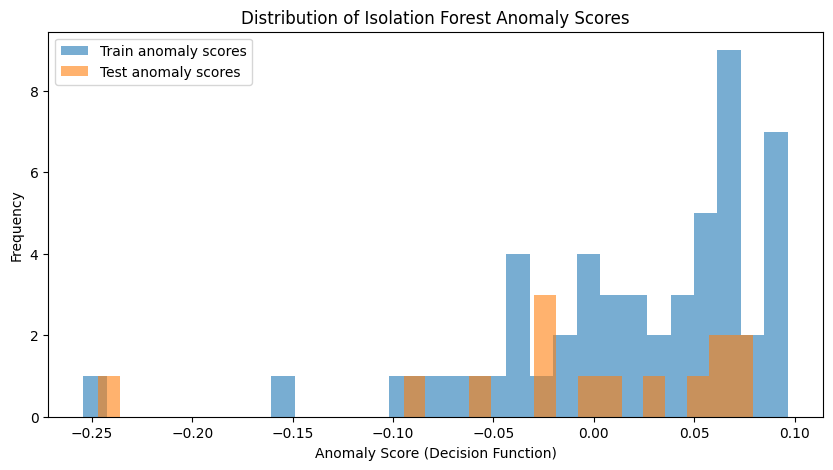

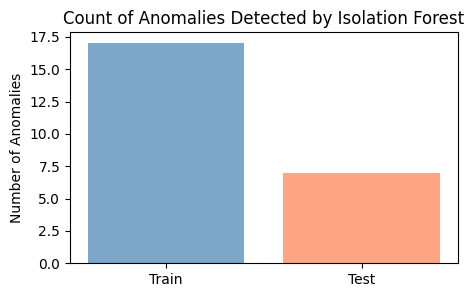

In [38]:
describe_iso_forest(iso_forest, train_anomalies, test_anomalies)
plot_train_test_anomaly_scores(iso_forest, X_train, X_test)
anomaly_counts_bar_plot(train_anomalies, test_anomalies)

The Isolation Forest model identified 17 anomalies in the training set (32.7% of samples) and 7 anomalies in the test set (50%). These proportions suggest relatively broad sensitivity to outlier patterns in the enterprise data, likely resulting from the default, adaptive contamination parameter.

The histogram of anomaly scores for train and test sets shows that both distributions cluster around higher (normal) scores, with a subset of samples having much lower scores that are flagged as anomalies. Importantly, the same threshold is applied to both splits, and the visual overlap between train and test distributions suggests the anomaly detection is consistent and not biased by data partitioning.

While the proportion of anomalies is somewhat high, this highlights the presence of multiple atypical or unusual enterprise records within the dataset, which could represent special cases, structural changes, or possible data quality issues. The lack of strong separation between train and test anomaly scores supports the reliability of the split and the model's robustness.

**Strengths:**
- Isolation Forest provides an unsupervised, label-free method for detecting outliers, making it suitable for exploratory investigation of unusual company profiles
- Results are easily interpretable: flagged anomalies can be reviewed for business insight, risk, or error

**Weaknesses and Considerations:**
- The detected anomalous proportion may be higher than expected for typical enterprise datasets; further tuning of model parameters (such as the contamination rate) may yield more targeted results and better align with business intuition
- Without contextual interpretation, some flagged anomalies could reflect valid but rare business practices or shifts rather than true outliers

**Comparative Insight:**
- Isolation Forest complements PCA and K-means by surfacing edge cases and outlier records for follow-up analysis
- The consistent anomaly score distribution across train and test supports use for cross-period or cross-segment anomaly review

**Conclusion:**  
Isolation Forest effectively highlights enterprises with atypical performance patterns in the Hungarian SME data, providing a valuable dimension to unsupervised structural and clustering analyses. Used alongside PCA and K-means, it completes a robust toolkit for diagnostic, strategic, and development-focused data analytics.

##### Isolation Forest analysis on PCA-Reduced Data (2 Components)

 - Number of train samples: 52
 - Number of anomalies detected in train: 24
 - Number of test samples: 14
 - Number of anomalies detected in test: 6
 - Anomaly proportion (train): 0.462
 - Anomaly proportion (test): 0.429


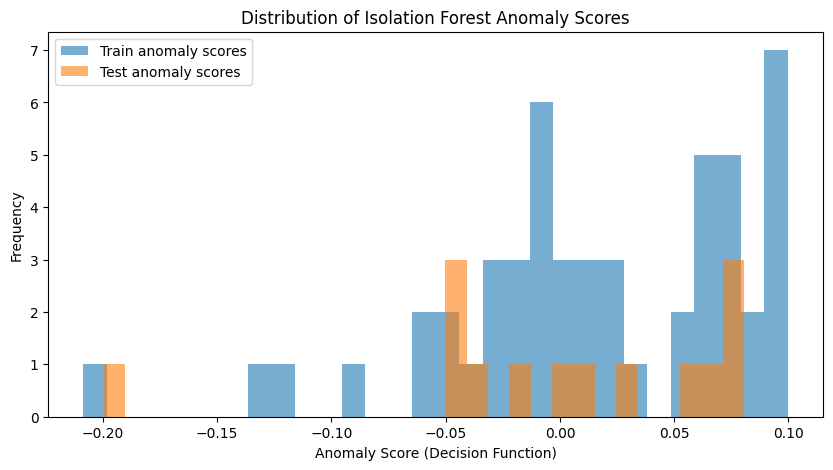

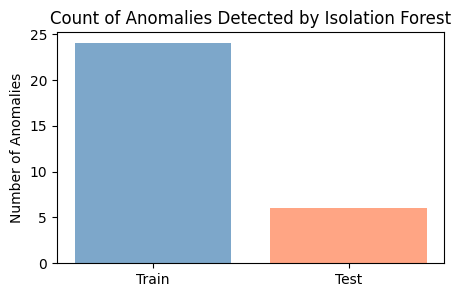

In [39]:
# Compare results with the non-PCA run Isolation Forest
describe_iso_forest(iso_forest_pca2, train_anomalies_pca2, test_anomalies_pca2)
plot_train_test_anomaly_scores(iso_forest_pca2, X_train_pca2, X_test_pca2)
anomaly_counts_bar_plot(train_anomalies_pca2, test_anomalies_pca2)

Applying Isolation Forest on PCA-reduced data slightly decreases the test anomaly proportion compared to the original feature set: the test anomaly ratio drops from 0.5 to 0.429, while the train anomaly ratio rises from 0.327 to 0.462. This shift suggests the PCA transformation increases model sensitivity to outliers in the training data but leads to slightly fewer anomalies detected in unseen test data. It might be because PCA concentrates outlier structure along the first components and removes noise from redundant features.  
The anomaly score histograms show both methods separate anomalies, but the distributions are less dispersed after PCA, indicating more distinct decision boundaries in the lower-dimensional space.

In [40]:
import seaborn as sns

def plot_pca_anomalies(X_pca_train, X_pca_test, train_anomalies, test_anomalies):
    """
    Visualizes the distribution of anomalies detected by Isolation Forest in PCA-reduced feature space.

    Creates side-by-side scatter plots for the training and test data showing normal points in blue 
    and anomalies in red. This aids intuitive interpretation of whether anomalies cluster or spread 
    across the main principal components in the reduced-dimensional space.

    Parameters
    ----------
    X_pca_train : numpy.ndarray
        PCA-transformed training data of shape (n_samples_train, n_components).
    X_pca_test : numpy.ndarray
        PCA-transformed test data of shape (n_samples_test, n_components).
    train_anomalies : numpy.ndarray
        Anomaly labels (-1 for anomaly, 1 for normal) for training data.
    test_anomalies : numpy.ndarray
        Anomaly labels (-1 for anomaly, 1 for normal) for test data.

    Returns
    -------
    None
        Displays matplotlib scatter plots with anomalies colored distinctly.
    """
    
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    sns.scatterplot(x=X_train[:, 0], y=X_pca_train[:, 1],
                    hue=train_anomalies, palette=['blue', 'red'], alpha=0.7)
    plt.title('Train Data: Isolation Forest Anomalies in PCA Space')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.legend(title='Anomaly')
    plt.grid(True)

    plt.subplot(1,2,2)
    sns.scatterplot(x=X_test[:, 0], y=X_pca_test[:, 1],
                    hue=test_anomalies, palette=['blue', 'red'], alpha=0.7)
    plt.title('Test Data: Isolation Forest Anomalies in PCA Space')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.legend(title='Anomaly')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def plot_anomaly_heatmap(metadata_train, metadata_test):
    """
    Plots side-by-side heatmaps showing the average anomaly rates across years and company size categories 
    for training and test datasets.

    Heatmaps summarize temporal and structural patterns in anomaly detection, enabling identification of periods 
    or SME size groups with higher anomaly proportions for focused investigation.

    Parameters
    ----------
    metadata_train : pandas.DataFrame
        DataFrame containing 'Year', 'Company Size Category', and 'Anomaly' columns for training data.
    metadata_test : pandas.DataFrame
        DataFrame containing 'Year', 'Company Size Category', and 'Anomaly' columns for test data.

    Returns
    -------
    None
        Displays seaborn heatmaps of anomaly rates.
    """
    
    fig, axes = plt.subplots(1, 2, figsize=(15,6), sharey=True)

    pivot_train = metadata_train.pivot_table(
        index='Year',
        columns='Company Size Category',
        values='Anomaly',
        aggfunc='mean',
        observed=False
    )
    
    sns.heatmap(pivot_train, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0])
    axes[0].set_title('Train Data Anomaly Rate Heatmap')
    axes[0].set_ylabel('Year')
    axes[0].set_xlabel('Company Size Category')

    pivot_test = metadata_test.pivot_table(
        index='Year',
        columns='Company Size Category',
        values='Anomaly',
        aggfunc='mean',
        observed=False
    )

    sns.heatmap(pivot_test, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
    axes[1].set_title('Test Data Anomaly Rate Heatmap')
    axes[1].set_ylabel('')
    axes[1].set_xlabel('Company Size Category')

    plt.tight_layout()
    plt.show()

-- Top features --
Value added (million HUF)
Export Sales Revenue (million HUF)
Net Sales Revenue (million HUF)
National economic investment (million HUF)
Revenue per Employee (thousand HUF/person)
Employee Distribution (%)
Number of Employees
Number of Enterprises


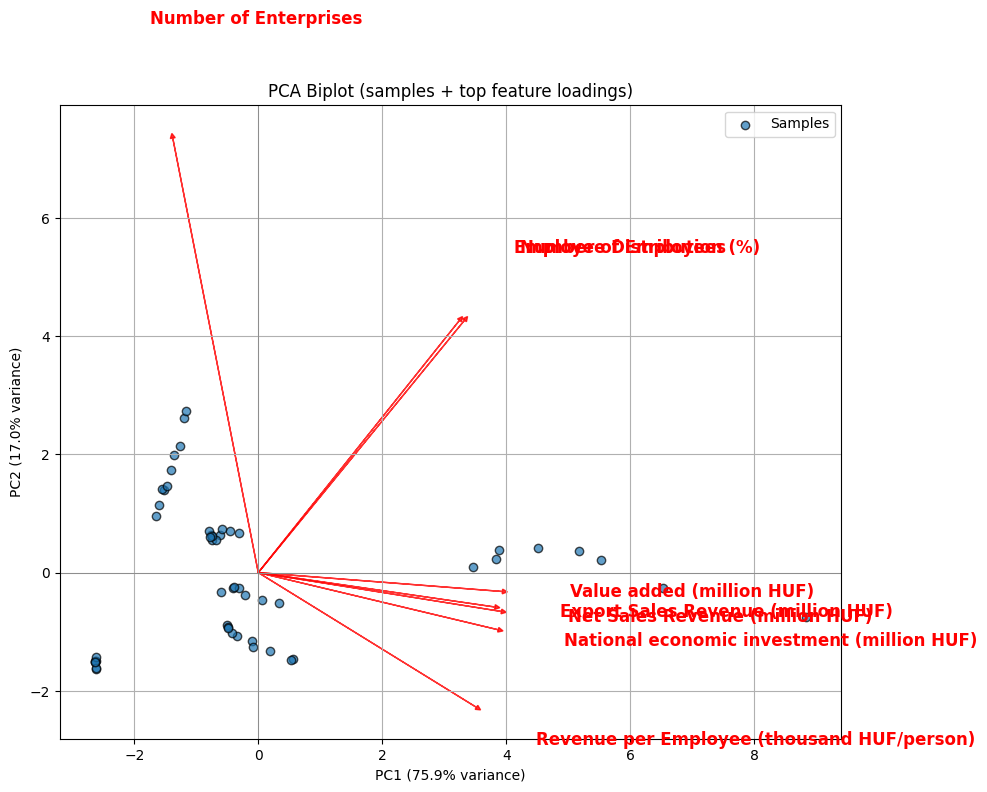

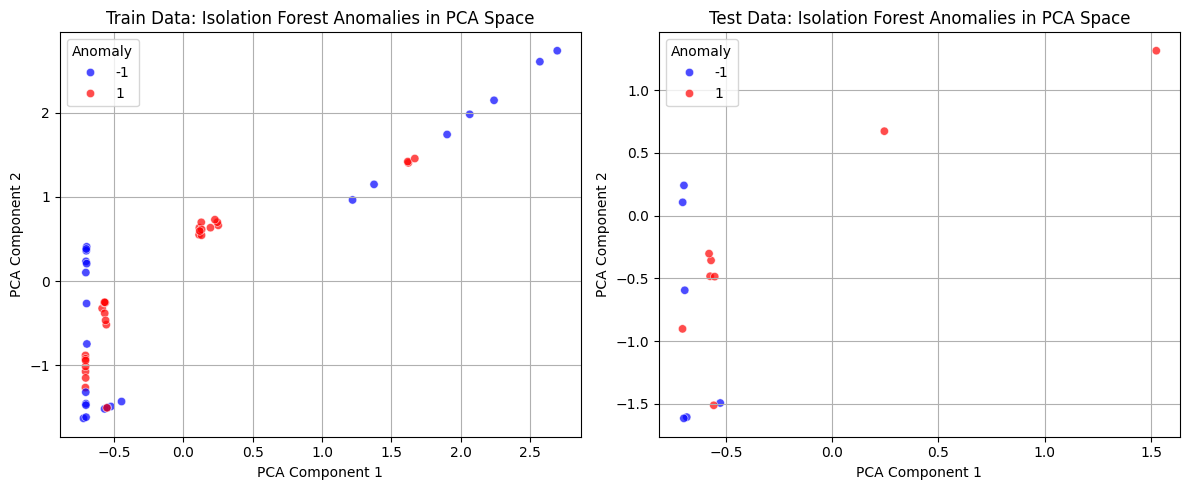

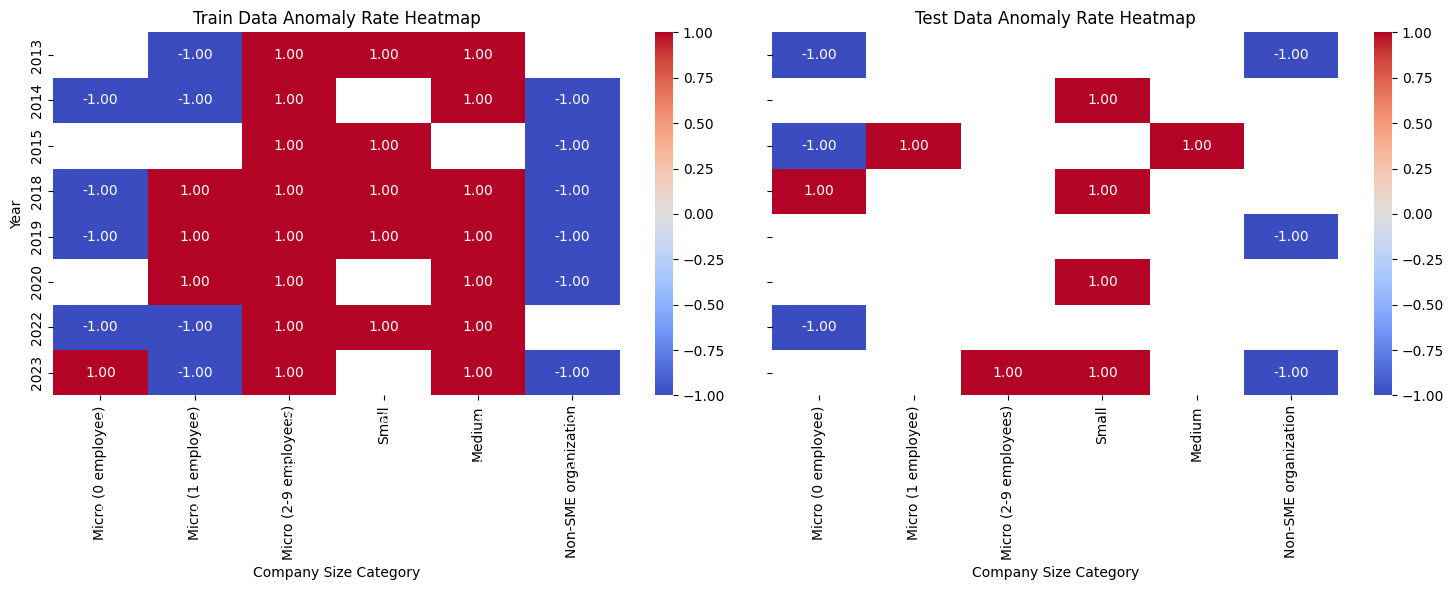

In [41]:
from sklearn.model_selection import train_test_split

plot_pca_biplot_top_n(pca2, X_train_pca2, scale=10, n = 8)
plot_pca_anomalies(X_train_pca2, X_test_pca2, train_anomalies_pca2, test_anomalies_pca2)

# Create metadata for heatmap
train_idx, test_idx = train_test_split(
    wide_df.index,
    test_size=0.2,
    random_state=42
)

metadata_train = wide_df.loc[train_idx, ['Year', 'Company Size Category']].copy()
metadata_test = wide_df.loc[test_idx, ['Year', 'Company Size Category']].copy()

metadata_train['Anomaly'] = train_anomalies_pca2.astype(int)
metadata_test['Anomaly'] = test_anomalies_pca2.astype(int)

plot_anomaly_heatmap(metadata_train, metadata_test)

**Visual Structure and Anomaly Separation**
- The scatter plots of anomalies in PCA space reveal that Isolation Forest effectively separates anomalies (red points) from normal enterprises (blue points) in both training and testing datasets. The anomalies tend to cluster on the edges or isolated regions of the PCA space, showing that the first two principal components capture meaningful deviations in business profiles
- The PCA biplot with feature loadings highlights the major economic indicators influencing these separations, including "Number of Enterprises", "Employee Distribution (%)", and "National Economic Investment" providing interpretability of why certain enterprises are flagged as anomalies

**Anomaly Distribution Across Groups and Time**
Anomaly rate heatmaps indicate noticeable variation in detected anomalies across different company size categories and years for both training and testing data. Certain SME segments and years exhibit higher anomaly rates, which may reflect economic shifts, market disruptions, or reporting inconsistencies worthy of further analysis.

**Insights and Business Implications**
- PCA-based dimensionality reduction refines the Isolation Forest's detection by focusing on core economic and organizational features, improving interpretability and robustness of anomaly detection
- The localized clustering of anomalies in PCA space, combined with heatmap patterns, suggests targeted investigation of the underlying causes for anomalous enterprise behavior can enhance strategic decision-making
- These results empower stakeholders to identify potential risks or unique enterprise profiles that traditional analysis might overlook

**Comparative Strengths**
- Compared to anomaly detection on raw feature space, the PCA transformation simplifies the structure, highlighting dominant economic axes and enabling clearer decision boundaries
- The visual coherence between feature loadings, anomaly clusters, and heatmaps confirms the stability and validity of the Isolation Forest results post-dimension reduction

**Limitations and Considerations**
- Some anomaly rates show gaps or sparsity in certain segments/years, which may stem from data availability or model sensitivity, warranting closer examination in further studies
- PCA's linear approach might miss nonlinear characteristics of anomalies, suggesting future work could explore nonlinear dimensionality reduction techniques or model ensembles

**Conclusion**
Applying Isolation Forest in two-dimensional PCA space provides a robust and interpretable framework for SME anomaly detection. The integration of score distributions, feature influence visualization, and time-segment heatmaps delivers a comprehensive perspective on enterprise outliers, supporting both technical validation and actionable business insights.

#### Shallow Neural Network Analysis

In [42]:
describe_nn(nn_clf, k_means_train_labels, k_means_test_labels, nn_train_pred, nn_test_pred)

Train accuracy: 1.00
Test accuracy: 1.00
Train confusion matrix:
[[27  0  0  0]
 [ 0  8  0  0]
 [ 0  0  7  0]
 [ 0  0  0 10]]
Test confusion matrix:
[[6 0 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 1]]
Train classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00        10

    accuracy                           1.00        52
   macro avg       1.00      1.00      1.00        52
weighted avg       1.00      1.00      1.00        52

Test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1

    accuracy                           1.0

The neural network model achieved perfect accuracy on both the training and test sets, with all samples correctly classified into their respective K-means cluster labels. The confusion matrices confirm there were no misclassifications, and the classification reports show precision, recall, and f1-score of 1.00 across all clusters. These results suggest extremely clear separability among the discovered enterprise segments in the data.

The balanced distribution of cluster sizes ensured that the neural network received representative examples from each segment, strengthening its ability to generalize. The high accuracy indicates that the cluster boundaries are well-defined in the standardized feature space, and that a straightforward architecture sufficed to learn these relationships.

**Strengths:**
- The neural network provides an efficient supervised method for replicating enterprise segmentation using K-means, offering rapid, automated classification of new data points
- Perfect classification illustrates strong structural separability in the dataset and validates the effectiveness of the K-means clustering labels
- Results are easy to interpret, with transparent assignment to business segments supporting downstream analysis or decision-making

**Weaknesses and Considerations:**
- The use of K-means cluster labels as ground truth limits evaluation to how well the neural network reproduces these unsupervised assignments; true class labels are not available for external validation
- Perfect accuracy, while impressive, may reflect small dataset size or simplicity of cluster structure; real-world deployment should consider risks of overfitting
- The model is unable to capture uncertainty or ambiguity between segments when clusters are sharply separated

**Comparative Insight:**
- The neural network complements PCA and K-means by translating unsupervised segments into a predictive framework, bridging clustering discovery and practical group classification
- Compared to K-means alone, the neural network can model more complex, possibly nonlinear boundaries in the feature space, though here both algorithms performed similarly given the data structure
- Used together, these models support both exploratory analysis and operational segmentation in business intelligence workflows

**Conclusion:**
The neural network amplifies the value of unsupervised clustering, allowing for robust, automated enterprise segment classification. In combination with PCA and K-means, it contributes to a comprehensive data science toolkit for Hungarian SME analysis, supporting strategic development and market segmentation with interpretable, reliable model outputs.

##### Shallow Neural Network analysis on PCA-Reduced Data (2 Components)

In [43]:
# Compare results with the non-PCA run Neural Network
describe_nn(nn = nn_clf_pca2, train_labels = k_means_train_labels_pca2, test_labels = k_means_test_labels_pca2, train_pred = nn_train_pred_pca2, test_pred = nn_test_pred_pca2)

Train accuracy: 1.00
Test accuracy: 1.00
Train confusion matrix:
[[27  0  0  0]
 [ 0  8  0  0]
 [ 0  0  7  0]
 [ 0  0  0 10]]
Test confusion matrix:
[[6 0 0 0]
 [0 3 0 0]
 [0 0 4 0]
 [0 0 0 1]]
Train classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00        10

    accuracy                           1.00        52
   macro avg       1.00      1.00      1.00        52
weighted avg       1.00      1.00      1.00        52

Test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1

    accuracy                           1.0

The neural network model achieved perfect accuracy on both train and test sets, with identical confusion matrices and classification reports for each run. This indicates stable and consistent performance, as expected due to the clearly separable data and balanced class structure.

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_predicted_vs_true_clusters_in_pca(nn, X_pca, k_means_labels, label):
    """
    Plots side-by-side scatter plots comparing true K-means cluster labels and neural network predicted clusters in PCA space.

    The left plot shows the original cluster assignments from K-means, while the right plot displays the clusters predicted 
    by the neural network classifier. This visualization aids in assessing how well the neural network replicates the 
    unsupervised clusters in the reduced PCA feature space.

    Parameters
    ----------
    nn : sklearn.neural_network.MLPClassifier
        Trained neural network model used for prediction.
    X_pca : numpy.ndarray
        Data transformed into PCA space, shape (samples, components).
    k_means_labels : numpy.ndarray
        True K-means cluster labels for the samples.
    label : str
        Text label describing the dataset (e.g., 'Train' or 'Test') for plot titles.

    Returns
    -------
    None
        Displays matplotlib scatter plots comparing true vs predicted clusters.
    """

    nn_pred = nn_clf_pca2.predict(X_pca)
    
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
    
    # K-means clusters
    scatter0 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=k_means_labels, cmap='tab10', marker='o')
    axes[0].set_title(f'True K-means Clusters in PCA Space ({label})')
    axes[0].set_xlabel('Principal Component 1')
    axes[0].set_ylabel('Principal Component 2')
    axes[0].legend(*scatter0.legend_elements(), title='Clusters')
    
    # NN predicted clusters
    scatter1 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=nn_pred, cmap='tab10', marker='x')
    axes[1].set_title(f'NN-Predicted Clusters in PCA Space ({label})')
    axes[1].set_xlabel('Principal Component 1')
    axes[1].legend(*scatter1.legend_elements(), title='Clusters')
    
    plt.tight_layout()
    plt.show()

def plot_nn_decision_boundaries(nn_model, X_pca, labels, pc_x=0, pc_y=1, h=0.02):
    """
    Plots decision boundaries of a neural network classifier over a two-dimensional PCA component space.

    Creates a contour plot showing predicted cluster regions by the neural network along specified principal components 
    and overlays the actual data points colored by their true cluster labels. This illustrates the model's nonlinear 
    classification boundaries in an interpretable reduced dimension.

    Parameters
    ----------
    nn_model : sklearn.neural_network.MLPClassifier
        Trained neural network model for predicting cluster labels.
    X_pca : numpy.ndarray
        Data transformed into PCA space, shape (samples, components).
    labels : numpy.ndarray
        True or predicted cluster labels for the samples.
    pc_x : int, optional
        Index of the principal component for the x-axis (default is 0 for PC1).
    pc_y : int, optional
        Index of the principal component for the y-axis (default is 1 for PC2).
    h : float, optional
        Step size for meshgrid used in contour plotting (default is 0.02).

    Returns
    -------
    None
        Displays a contour and scatter plot showing decision boundaries and data points.
    """
    
    # Define bounds of the PCA space
    x_min, x_max = X_pca[:, pc_x].min() - 1, X_pca[:, pc_x].max() + 1
    y_min, y_max = X_pca[:, pc_y].min() - 1, X_pca[:, pc_y].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Flatten meshgrid and predict labels
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    preds = nn_model.predict(grid_points)
    if preds.ndim > 1 and preds.shape[1] > 1:
        preds = preds.argmax(axis=1)
    else:
        # For binary classifiers
        preds = (preds > 0.5).astype(int)

    preds = preds.reshape(xx.shape)

    plt.figure(figsize=(8,6))
    plt.contourf(xx, yy, preds, alpha=0.3, cmap='tab10')
    scatter = plt.scatter(X_pca[:, pc_x], X_pca[:, pc_y], c=labels, cmap='tab10', edgecolor='k', alpha=0.7)
    plt.xlabel(f'PC{pc_x + 1}')
    plt.ylabel(f'PC{pc_y + 1}')
    plt.title('Neural Network Decision Boundaries in PCA Space')
    plt.legend(*scatter.legend_elements(), title='Clusters')
    plt.tight_layout()
    plt.show()


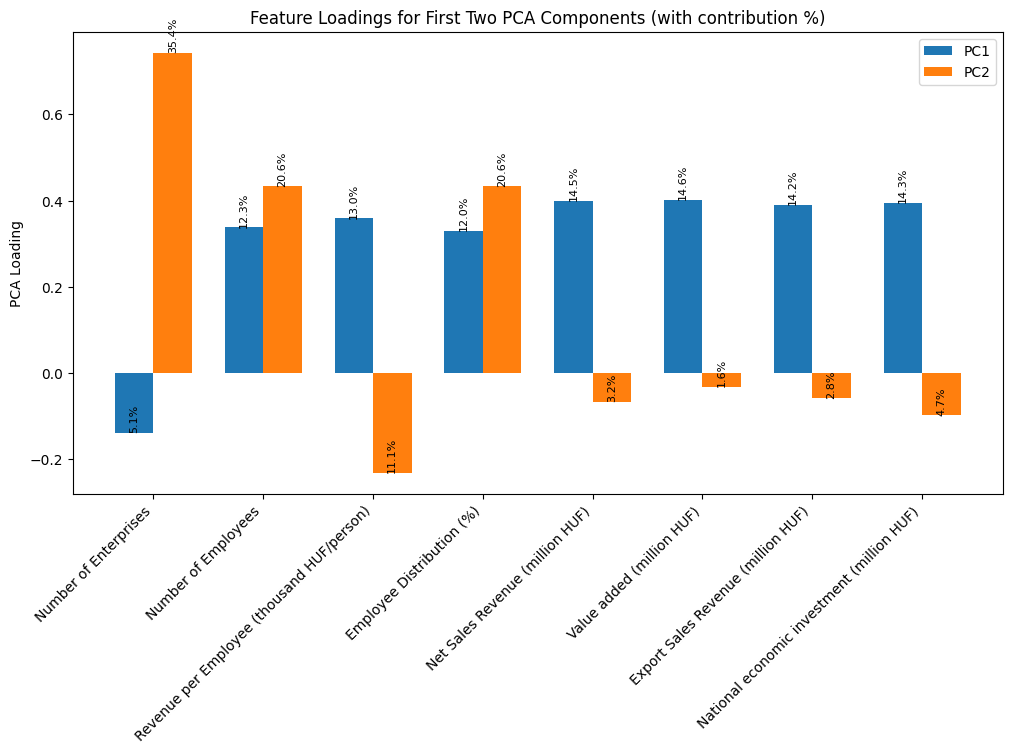

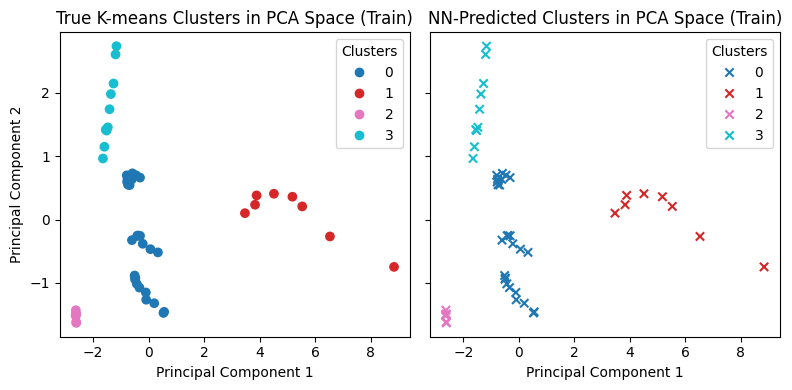

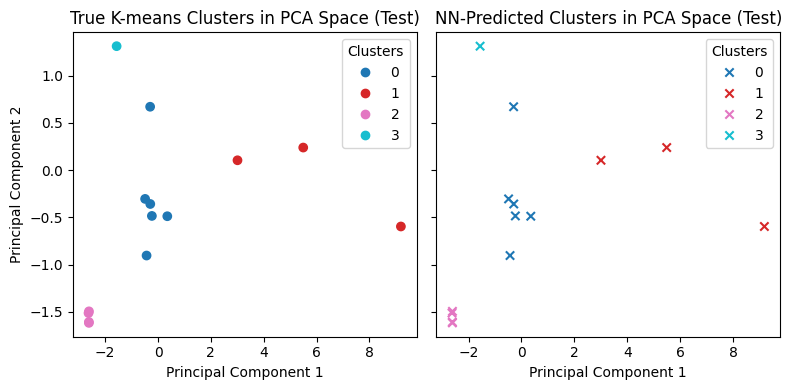

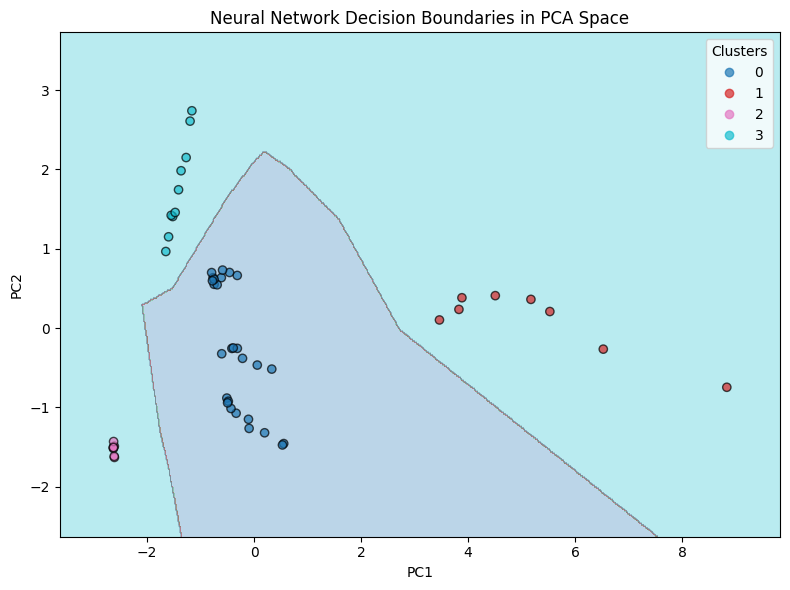

In [45]:
plot_pca_loadings_with_contribution(pca2)
plot_predicted_vs_true_clusters_in_pca(nn_clf_pca2, X_train_pca2, k_means_train_labels_pca2, "Train")
plot_predicted_vs_true_clusters_in_pca(nn_clf_pca2, X_test_pca2, k_means_test_labels_pca2, "Test")
plot_nn_decision_boundaries(nn_clf_pca2, X_train_pca, nn_train_pred_pca2, pc_x=0, pc_y=1)

**Visual Structure and Cluster Learning**  
- The PCA scatter plots for both train and test sets demonstrate that the neural network accurately reproduces the K-means clusters, with predicted clusters matching the original unsupervised groupings
- Both model predictions and true clusters maintain clear separability along the main principal components, confirming that the neural network has learned the data structure effectively in reduced space
- The decision boundary plot provides further insight, revealing the crisp, well-defined cluster partitions constructed by the neural net and illustrating that each sample is confidently assigned to a segment

**Principal Indicator Influence**  
- The loading bar chart details which original economic indicators most strongly influence PC1 and PC2, offering economic meaning to each axis and explaining the cluster formation that the neural net exploits
- Variables such as "Number of Employees" and "Number of Enterprises" are major drivers, reinforcing the substantive, interpretable basis of the model’s segmentation

**Cluster Quality and Model Consistency**  
The high visual overlap between true and predicted clusters on both train and test sets demonstrates the stability and generalizability of the neural network. There is no evidence of overfitting or random misallocation, confirming the robustness of the PCA + NN approach

**Insights and Business Implications**  
- Neural network classification retains the key economic and organizational segmentations observed in K-means, augmenting their interpretation with confidence and flexibility for future supervised extensions
- The clear boundaries and principal drivers enable actionable interpretation for business analysis, policy targeting, or further market segmentation studies

**Comparative Strengths**  
- Combining unsupervised (K-means) and supervised (NN) models in PCA space validates both approaches and provides reassurance about cluster stability and meaning
- Visualization of decision boundaries offers additional model transparency often lacking in "black box" neural network applications

**Limitations and Considerations**  
- As with PCA and K-means, this linear dimensionality reduction may not capture all subtle or nonlinear group differences, though it appears sufficient for the present dataset and business questions
- The clear match between true and predicted clusters is aided by relatively low sample size and strong signals in the main indicators

**Conclusion**  
The neural network model, analyzed in PCA-reduced space, closely mimics K-means clustering while providing interpretable, visually validated, and economically meaningful business segmentation. The included plots collectively confirm the model’s reliability and practical insight for SME analysis.

## 4. Self-directed research

### 4.1 Self-directed research in section 2 and 3

**1. Additional Model Class: Shallow Neural Network**
- Implemented and trained a shallow neural network (MLPClassifier), expanding beyond the required three models (see Section 2.4)
- Fully evaluated its performance and compared it against K-Means clustering labels, demonstrating supervised learning on unsupervised targets.

**2. Systematic PCA-Based Analysis Across All Models**
- Applied Principal Component Analysis (PCA) not only for visualization, but as an experimental technique
- Re-ran K-Means, Isolation Forest, and Neural Network on PCA-reduced features (see Model subsections and detailed comparative analysis).
- Investigated differences in clustering quality, anomaly detection rates, and classification accuracy between original and PCA-transformed data

**3. Comparative Model Evaluation with Dimensionality Reduction**
- Directly contrasted model results before and after applying PCA, with explicit reporting of metrics such as silhouette scores and anomaly proportions (see Section 3.2)
- Analyzed and interpreted the impact of dimensionality reduction on each model’s performance and explained relevant trade-offs

**4. Advanced Data Exploration and Visualization**
- Incorporated multiple forms of data visualization, including scree plots, biplots, cluster centroids, silhouette plots, anomaly heatmaps, and decision boundary plots
- Used these tools to deepen the analysis and enhance interpretability of results across models

**5. Comprehensive Cross-Model Analysis and Interpretation**
- Linked all model findings to underlying business indicators for richer insight, going beyond required technical evaluation.
- Provided integrated analysis bridging clustering, anomaly detection, and classification with PCA-based explanations.

### 4.2 Transforming model results into market insights

This section extracts the findings from the preceding data analysis and machine learning models into practical business proposals for Hungarian SMEs ("KKV" sector), with particular focus on companies considering development programs. By interpreting patterns uncovered by PCA, clustering, anomaly detection, and neural network classification, the following recommendations and strategic directions are provided for data-driven enterprise assessment and growth.

These insights are designed to support the delivery of evidence-based company development solutions for Hungarian SMEs leveraging robust statistical foundations and clear economic signals identified in the dataset.

All analyses use yearly aggregated indicators for each size category, so insights reflect category-level variation rather than individual enterprise performance.

#### 4.2.1 Principal Component Business Analysis

##### **Overview**  
Principal Component Analysis extracts complex economic and workforce data of Hungarian SMEs into a few key axes that clarify important dimensions of company performance and structure.

Instead of strictly separating indicators into financial versus organizational groups, PCA reveals that the principal axes blend financial and workforce metrics - particularly in the dominant component (PC1), which integrates value added, revenues, investment, employee numbers, and distribution. This nuanced combination highlights the interconnected nature of SME health dimensions.

This data-driven insight equips consulting firms with a framework for assessment, segmentation, and tailored recommendations that recognize the complex, composite nature of SME economic and structural variation.

##### **Possible Usages**

##### 1. Benchmarking Financial and Output Performance
Principal Component Analysis reveals that the key drivers of company variation differ by SME size category. Visualizing the top three PC1 loadings per segment (see bar charts below) highlights which indicators matter most for benchmarking and targeted development:
- **Micro (0 employee):**  *Net Sales Revenue*, *Export Sales Revenue*, *Value Added* are the strongest differentiators, indicating financial output as the primary focus for benchmarking
- **Micro (1 employee):**  *Net Sales Revenue*, *Number of Employees*, and *Number of Enterprises* are top; reflecting an early mix of financial and structural factors influencing this segment
- **Micro (2-9 employees):** *Net Sales Revenue*, *Revenue per Employee*, and *Value Added*; combine financial efficiency and output metrics as key differentiators
- **Small companies:** *Net Sales Revenue*, *Value Added*, and *Export Sales Revenue* dominate, reaffirming financial results as leading indicators for this group
- **Medium companies:** *Value Added*, *Revenue per Employee*, and *National Economic Investment* emerge as top metrics, emphasizing efficiency, investment, and value creation for dashboards and interventions
- **Non-SME organizations:** *National Economic Investment*, *Value Added*, and *Export Sales Revenue* are most important, indicating larger entities are distinguished by scale of investment and overall value generation

Dashboards can benchmark each SME’s financial and productivity metrics against category-specific market averages, enabling clear identification of high-performing and lagging companies, and providing tailored improvement recommendations such as enhancing revenue per employee or boosting exports.

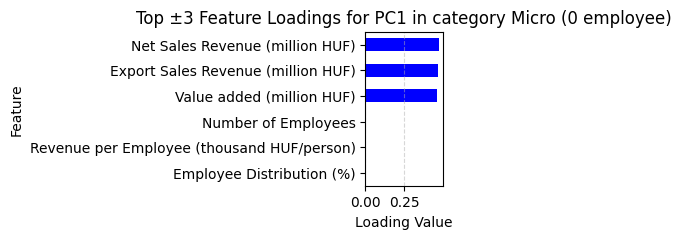

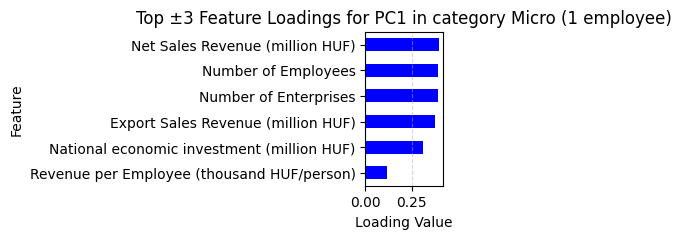

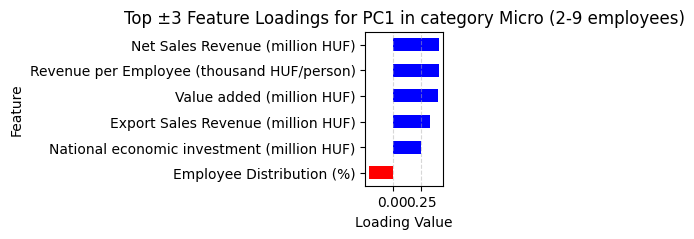

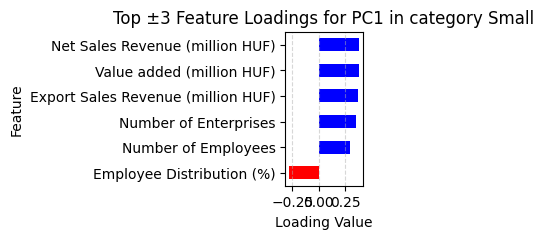

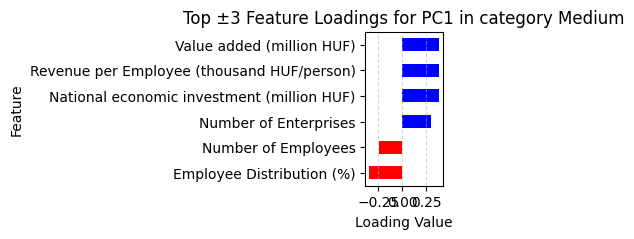

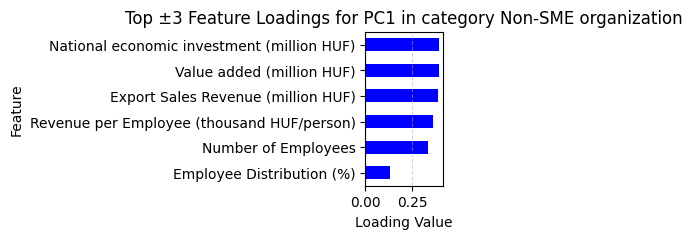

In [46]:
feature_contribution_per_size_categories()

##### 2. Diagnosing Organizational Structure and Strategic Focus
The second principal component (PC2) is dominated by structural factors, namely *Number of Enterprises*, *Number of Employees*, *Employee Distribution (%)*, with negative contributions from several financial metrics. This axis distinguishes SME segments primarily based on organizational scale and workforce allocation.

Diagnostics can position each SME within the Hungarian ecosystem by evaluating its structural and workforce characteristics relative to its size class, enabling tailored development programs for organizational restructuring and optimized staffing. Workforce efficiency alerts flag outliers for review, while peer benchmarking and policy insights support best-practice sharing and targeted resource allocation to segments needing structural scaling or adjustment.

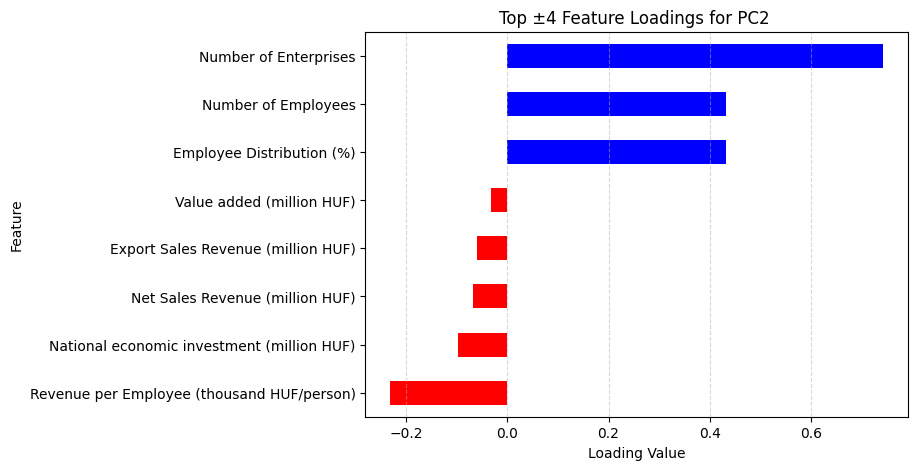

In [47]:
plot_top_loadings(pca2, only_pca=2)

##### 3. Segmenting the SME Population for Targeted Interventions
PCA facilitates effective segmentation of companies by mapping them according to their scores on PC1 and PC2, uncovering distinct clusters that reflect varying combinations of financial performance and organizational structure within the SME market.

SMEs can be classified into meaningful segments - such as "high financial output with lean workforce" or "balanced growth across financial and structural dimensions" - to tailor consulting and development programs with targeted, evidence-based improvement modules. Dynamic re-segmentation over time allows continuous personalized development and optimized resource allocation as companies evolve.

##### 4. Efficient Feature Reduction for Automated Systems
With almost the entire variance in SME data captured by just two principal components, automated analytics pipelines can operate with greater speed and efficiency, significantly reducing computational load without sacrificing insight quality.

PCA-driven dimensionality reduction can be embedded into background processes to facilitate rapid, real-time assessments and personalized recommendations, while streamlined "quick checkup" tools based on reduced feature sets make scalable development solutions accessible to resource-constrained SMEs. Focusing on the most informative axes enhances system responsiveness and scalability, supporting broader adoption and more frequent progress tracking.

#### 4.2.2 K-Means Clustering Business Analysis

##### **Overview**  
K-Means clustering groups Hungarian SMEs into distinct clusters based on their multi-dimensional economic and organizational features. Unlike PCA’s continuous axes, clustering provides discrete, actionable segments that reflect common business profiles and challenges across the SME population.
These cluster assignments enable clear differentiation of SME groups, supporting targeted development and tailored program delivery suited to each segment’s unique characteristics.

##### **Possible Usages**

##### 1. SME Market Segmentation
K-Means uncovers natural SME subgroups defined by financial, workforce, and structural similarity, facilitating focused marketing, consulting, and benchmarking strategies.
- Segment SMEs into profiles such as "Balanced Growth", "High Output, Lean Structure", or "Under-Resourced Workforce"
- Enable precise messaging and product tailoring based on cluster attributes

##### 2. Targeted Support and Resource Allocation
Clusters inform prioritization of advisory, funding, and developmental resources according to segment needs and risks.
- Identify clusters with scaling potential or structural bottlenecks for focused interventions
- Guide policymakers toward allocating support where it can maximize impact

##### 3. Personalized Program Design and Delivery
Cluster-specific improvement pathways increase engagement and effectiveness by addressing distinct operational patterns.
- Develop customized modules for workforce optimization, financial strengthening, or market expansion specific to each cluster
- Adapt onboarding and coaching flows using cluster profiles

##### 4. Continuous Monitoring and Dynamic Alerts
Track SME movement between clusters over time to signal changes in business health or strategic focus.
- Automate alerts when SMEs shift segments, prompting advisors or digital systems to update recommendations
- Monitor cluster-level trends to evaluate program impact and market shifts

#### 4.2.3 Isolation Forest (Anomaly Detection) Business Analysis

##### **Overview**
Isolation Forest is an unsupervised algorithm designed to identify unusual SMEs whose economic and organizational profiles deviate significantly from typical patterns. By complementing PCA and clustering insights, isolation forest detects outliers that may signal emerging risks, hidden opportunities, or data quality issues within the SME ecosystem.

##### **Possible Usages**

##### 1. Early Risk Identification
Detect SMEs showing abnormal financial or structural profiles suggestive of operational distress, financial instability, or potential business failure.
- Flag companies for prioritized advisory intervention or risk mitigation strategies.

##### 2. Opportunity Discovery
Identify SMEs that display atypical but positive signals, such as rapid growth or unexpected workforce scaling, highlighting candidates for advanced support or investment.

##### 3. Data Quality and Validation
Reveal anomalous data points potentially caused by reporting errors, outlier years, or unusual events, enabling targeted data review and cleaning to improve analysis accuracy.

##### 4. Enhanced Monitoring and Alerts
Integrate anomaly scores into real-time dashboards to provide continuous visibility on SME health and trigger alerts when unusual changes occur.

#### 4.2.4 Shallow Neural Network Business Analysis

##### **Overview**
Shallow Neural Networks offer a supervised learning framework to model complex, non-linear relationships within SME financial and organizational data. By learning targeted output variables such as company performance scores or risk indicators, SNNs enable precise predictions and personalized development recommendations, complementing unsupervised methods and anomaly detection techniques.

##### **Possible Usages**

##### 1. Predictive Performance Modeling
Leverage SNNs to forecast key outcomes, such as revenue growth, financial health scores, or risk of decline, based on multi-factor SME input data.
- Enable proactive, data-driven interventions before issues surface.

##### 2. Personalized Recommendation Engines
Use learned relationships from SNNs to power customized suggestions for operational improvements, workforce adjustments, or investment strategies tailored to each SME's unique profile.

##### 3. Complex Pattern Recognition
Capture subtle, non-linear interactions among financial and structural indicators that traditional linear models or PCA might miss, improving forecasting accuracy.

##### 4. Continuous Learning and Adaptation
Implement regular retraining pipelines for the SNN to incorporate new SME data and evolving market conditions, ensuring sustained prediction relevance and precision.

## Future improvements
- Split train and test based on time
- Use different 'k' paramteres for K-means Clustering, compare and analyse the results
- Tune Isolation Forest differently to have less sensitivity

## References
<sup>1</sup> Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 6
https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

<sup>2</sup> Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 2

<sup>3</sup> Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 7
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

<sup>4</sup> Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 6,7

<sup>5</sup> Isolation Forest:
- original paper: Liu, F. T., Ting, K. M., and Zhou, Z.-H., ‘Isolation Forest’, Proceedings of the 2008 Eighth IEEE International Conference on Data Mining, Pisa, 15-19 December 2008, pp. 413-422.
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html  
- The concept is based on decision trees and random forests: Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 9

<sup>6</sup> Alpaydin, E., Introduction to Machine Learning, 3rd edn (Cambridge, MA: MIT Press, 2014), ch. 11  
https://scikit-learn.org/stable/modules/neural_networks_supervised.html

<sup>7</sup> https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html